# 🕵️ Dolandırıcılık (Fraud) Tespiti — Keşifsel Veri Analizi + Ön İşleme

Bu notebook **model eğitmez**. Sadece şunları yapar:

1. Veriyi yükler, genel bakış verir
2. **Hedef değişkeni** (fraud etiketi) otomatik bulur ve doğrular
3. Eksik değer / tekrar eden satır kontrolü
4. **İstatistiksel özet**
5. **Histogram, Boxplot, Scatterplot**, korelasyon, kategorik analiz, zaman analizi
6. **Özellik üretimi → Encoding → Ölçekleme → Özellik seçimi**
7. Temiz train/test verisini `islenmis_veri/` klasörüne kaydeder

> **Nasıl çalıştırılır:** CSV ile aynı klasörde terminalde `jupyter lab` yaz → tarayıcıda `http://localhost:8888` açılır.
> Sonra menüden **Run → Run All Cells**.

> ⚠️ Her hücrenin üstündeki açıklamayı oku; kodların içindeki Türkçe yorumlar ne yaptığını anlatıyor.

## 0. Kurulum ve Ayarlar
Burası tek **değiştirmen gereken** yer. Çoğu zaman hiçbir şeyi değiştirmen gerekmez:
- `CSV_PATH = None` → klasördeki en büyük `.csv` dosyasını otomatik bulur
- `TARGET_COL = None` → fraud etiketi sütununu otomatik bulur (bulamazsa sana söyler)

In [1]:
import os, re, glob, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# ---------- ✏️ SENİN AYARLARIN ----------
CSV_PATH    = "synthetic_fraud_dataset.csv"   # None yaparsan klasördeki en büyük csv'yi otomatik bulur
TARGET_COL  = "Fraud_Label"                   # None yaparsan hedefi otomatik bulur
EKSTRA_ATILACAK = []    # elle atmak istediğin sütunlar, örn: ["Risk_Score"] (sızıntı analizinden sonra karar ver)
SAMPLE_N    = 100_000   # grafikler için en fazla kaç satır çizilsin (büyük veride tarayıcı donmasın)
GRAFIK_SAYISI = 16      # histogram/boxplot gridlerinde kaç özellik gösterilsin
ID_ESIGI    = 0.20      # bir metin sütununun benzersiz oranı bunun üstündeyse "ID" sayılıp atılır
RANDOM_STATE = 42
# ----------------------------------------

# Güzel görünüm ayarları
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (10, 5),
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Sabit renkler: normal = yeşilimsi, fraud = kırmızı (tüm grafiklerde aynı olsun)
PAL = {0: "#2a9d8f", 1: "#e63946"}
ETIKET = {0: "Normal", 1: "Fraud"}

## 1. Veriyi Yükleme ve İlk Bakış
`head()` ilk satırları, `info()` sütun tiplerini ve dolu/boş sayısını gösterir.

In [2]:
# Verilen dosya yoksa uyarı verip otomatik aramaya geç
if CSV_PATH is not None and not os.path.exists(CSV_PATH):
    print(f"⚠️ '{CSV_PATH}' bulunamadı, klasördeki csv dosyaları aranıyor...")
    CSV_PATH = None

# CSV yolu verilmediyse klasördeki .csv dosyalarını boyuta göre sıralayıp en büyüğünü al
if CSV_PATH is None:
    csv_listesi = sorted(glob.glob("*.csv"), key=os.path.getsize, reverse=True)
    if not csv_listesi:
        raise FileNotFoundError("Bu klasörde .csv bulunamadı. Yukarıda CSV_PATH değişkenine dosya yolunu yaz.")
    CSV_PATH = csv_listesi[0]
    print("Klasörde bulunan CSV'ler:", csv_listesi)

print("✅ Kullanılan dosya:", CSV_PATH)
df = pd.read_csv(CSV_PATH)
print(f"Satır sayısı: {df.shape[0]:,}   |   Sütun sayısı: {df.shape[1]}")
df.head()

✅ Kullanılan dosya: synthetic_fraud_dataset.csv
Satır sayısı: 50,000   |   Sütun sayısı: 21


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,Previous_Fraudulent_Activity,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend,Fraud_Label
0,TXN_33553,USER_1834,39.7900,POS,2023-08-14 19:30:00,"93,213.1700",Laptop,Sydney,Travel,0,0,7,437.6300,3,Amex,65,883.1700,Biometric,0.8494,0,0
1,TXN_9427,USER_7875,1.1900,Bank Transfer,2023-06-07 04:01:00,"75,725.2500",Mobile,New York,Clothing,0,0,13,478.7600,4,Mastercard,186,"2,203.3600",Password,0.0959,0,1
2,TXN_199,USER_2734,28.9600,Online,2023-06-20 15:25:00,"1,588.9600",Tablet,Mumbai,Restaurants,0,0,14,50.0100,4,Visa,226,"1,909.2900",Biometric,0.8400,0,1
3,TXN_12447,USER_2617,254.3200,ATM Withdrawal,2023-12-07 00:31:00,"76,807.2000",Tablet,New York,Clothing,0,0,8,182.4800,4,Visa,76,"1,311.8600",OTP,0.7935,0,1
4,TXN_39489,USER_2014,31.2800,POS,2023-11-11 23:44:00,"92,354.6600",Mobile,Mumbai,Electronics,0,1,14,328.6900,4,Mastercard,140,966.9800,Password,0.3819,1,1


In [3]:
# Sütun tipleri, boş olmayan değer sayısı ve bellek kullanımı
df.info()
print()
# Kaç sütun sayısal, kaç sütun metin?
print(df.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Transaction_ID                50000 non-null  object 
 1   User_ID                       50000 non-null  object 
 2   Transaction_Amount            50000 non-null  float64
 3   Transaction_Type              50000 non-null  object 
 4   Timestamp                     50000 non-null  object 
 5   Account_Balance               50000 non-null  float64
 6   Device_Type                   50000 non-null  object 
 7   Location                      50000 non-null  object 
 8   Merchant_Category             50000 non-null  object 
 9   IP_Address_Flag               50000 non-null  int64  
 10  Previous_Fraudulent_Activity  50000 non-null  int64  
 11  Daily_Transaction_Count       50000 non-null  int64  
 12  Avg_Transaction_Amount_7d     50000 non-null  float64
 13  F

### Zaman Sütununu Tarihe Çevirme
`Timestamp` gibi sütunlar CSV'den **metin** olarak gelir (örn. `"2023-08-14 19:30:00"`). Metin olarak hiçbir işe yaramaz;
tarihe çevirip **saat, haftanın günü, ay, gece mi?** gibi anlamlı sayılara bölüyorum. Fraud'lar genelde belli saatlerde yoğunlaşır.

In [4]:
zaman_cols = []
for c in list(df.columns):
    # Adında time/date geçen metin sütunlarını tarihe çevirmeyi dene
    metin_mi = pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object
    if metin_mi and any(k in str(c).lower() for k in ["time", "date", "tarih", "zaman"]):
        dt = pd.to_datetime(df[c], errors="coerce")
        if dt.notna().mean() > 0.9:                      # değerlerin %90'ından fazlası tarihe çevrildiyse kabul et
            df[c] = dt
            zaman_cols.append(c)
            df["saat"] = dt.dt.hour                       # 0-23
            df["haftanin_gunu"] = dt.dt.dayofweek         # 0=Pazartesi ... 6=Pazar
            df["ay"] = dt.dt.month
            df["gece_mi"] = dt.dt.hour.between(0, 5).astype(int)   # 00:00-05:59 arası mı?
            print(f"✅ '{c}' tarihe çevrildi → saat, haftanin_gunu, ay, gece_mi sütunları üretildi")
            print(f"   Tarih aralığı: {dt.min()}  →  {dt.max()}")
            break
df[[c for c in ["saat", "haftanin_gunu", "ay", "gece_mi"] if c in df.columns]].head()

✅ 'Timestamp' tarihe çevrildi → saat, haftanin_gunu, ay, gece_mi sütunları üretildi
   Tarih aralığı: 2023-01-01 00:01:00  →  2023-12-31 23:50:00


,saat,haftanin_gunu,ay,gece_mi
0,19,0,8,0
1,4,2,6,1
2,15,1,6,0
3,0,3,12,1
4,23,5,11,0


## 2. Hedef Değişkeni (Target) Doğru Seçme 🎯

Fraud projesinde hedef: **"bu işlem dolandırıcılık mı? (1) / değil mi? (0)"** sütunudur.
Doğru hedefi seçmek için şu mantığı kullanıyorum:

1. Sütun adı bilinen fraud isimlerinden biriyse (`Class`, `isFraud`, `fraud`, `label`, `target` …) **ve** tam 2 farklı değeri varsa → hedef budur.
2. Adı içinde `fraud` geçen ikili (2 değerli) bir sütun varsa → o.
3. Hiçbiri yoksa: **ikili olan ve azınlık sınıfı %20'nin altında** olan sütun (fraud her zaman nadirdir).

Sonra etiketi **0 = normal, 1 = fraud** formatına çeviririm (azınlık sınıf = fraud).
Hedef yanlış seçilirse sonraki her şey yanlış olur, bu yüzden aşağıda çıktıya mutlaka bak!

In [5]:
def hedef_bul(df):
    """Fraud etiketi olabilecek sütunu bulur. (sütun_adı, neden) döndürür."""
    kucuk = {str(c).lower().strip(): c for c in df.columns}   # küçük harf -> gerçek ad
    ikili = [c for c in df.columns if df[c].nunique(dropna=True) == 2]  # sadece 2 değerli sütunlar

    # 1) Bilinen fraud etiket isimleri
    bilinen = ["fraud_label", "class", "isfraud", "is_fraud", "fraud", "fraud_bool", "fraudulent",
               "is_fraudulent", "fraud_flag", "label", "target", "dolandiricilik", "y"]
    for a in bilinen:
        if a in kucuk and kucuk[a] in ikili:
            return kucuk[a], f"sütun adı bilinen bir fraud etiketi ('{kucuk[a]}') ve 2 değerli"

    # 2) Adında 'fraud' geçen ikili sütun (ör. isFlaggedFraud da olabilir; en az 'flag' içermeyeni tercih et)
    fraud_adli = [c for c in ikili if "fraud" in str(c).lower() or "dolandir" in str(c).lower()]
    fraud_adli.sort(key=lambda c: ("flag" in str(c).lower()) + ("previous" in str(c).lower()) + ("prev" in str(c).lower()))
    if fraud_adli:
        return fraud_adli[0], "adında 'fraud' geçen ikili sütun"

    # 3) Yedek plan: azınlık sınıfı %20'den küçük olan ikili sütun
    adaylar = []
    for c in ikili:
        oran = df[c].value_counts(normalize=True).min()
        if oran < 0.20:
            adaylar.append((oran, c))
    if adaylar:
        adaylar.sort()
        return adaylar[0][1], f"yedek kural: ikili ve azınlık oranı %{adaylar[0][0]*100:.2f} (EMİN DEĞİLİM, kontrol et!)"
    return None, None


if TARGET_COL is None:
    TARGET_COL, neden = hedef_bul(df)
    if TARGET_COL is None:
        raise ValueError("Hedef sütun otomatik bulunamadı. Yukarıdaki ayarlarda TARGET_COL = 'sütun_adı' yaz.")
    print(f"🎯 Seçilen hedef sütun: '{TARGET_COL}'  →  neden: {neden}")
else:
    print(f"🎯 Elle verilen hedef sütun: '{TARGET_COL}'")

T = TARGET_COL

# Hedefi boş olan satırlar işe yaramaz
df = df.dropna(subset=[T]).reset_index(drop=True)

# Etiketi 0/1'e çevir. Zaten 0/1 ise dokunma; değilse azınlık sınıf = fraud = 1 yap.
if set(df[T].unique()) == {0, 1}:
    df[T] = df[T].astype(int)
else:
    azinlik = df[T].value_counts().idxmin()
    print(f"   Değerler {sorted(map(str, df[T].unique()))} → '{azinlik}' = 1 (fraud), diğeri = 0")
    df[T] = (df[T] == azinlik).astype(int)

if df[T].mean() > 0.5:
    print("⚠️ UYARI: 1 etiketi çoğunluk sınıfı çıktı. Fraud'u doğru sütunda mı arıyorsun? TARGET_COL'u kontrol et.")

🎯 Elle verilen hedef sütun: 'Fraud_Label'


### Sınıf Dağılımı
Gerçek fraud verisinde **sınıf dengesizliği** (class imbalance) neredeyse her zaman vardır (fraud %1'in altında). Sentetik veri setlerinde oran daha dengeli çıkabilir; aşağıdaki oranı yorumla.
Dengesizlik büyükse **accuracy kullanmayacağız**: model "hep normal" dese bile %99+ doğruluk alır ama hiçbir fraud'u yakalamaz.
Onun yerine **Precision, Recall, F1 ve PR-AUC** bakacağız.

Normal (0): 33,933  (%67.866)
Fraud  (1): 16,067  (%32.134)
Dengesizlik oranı: yaklaşık 1 fraud'a karşı 2 normal


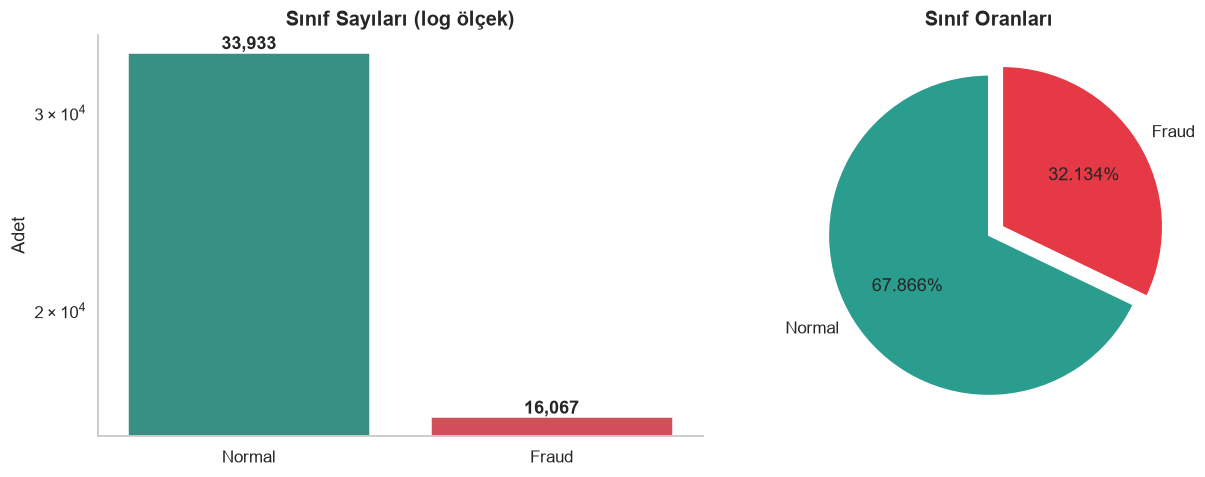

In [6]:
sayilar = df[T].value_counts().sort_index()
oranlar = df[T].value_counts(normalize=True).sort_index() * 100
print(f"Normal (0): {sayilar[0]:,}  (%{oranlar[0]:.3f})")
print(f"Fraud  (1): {sayilar.get(1, 0):,}  (%{oranlar.get(1, 0):.3f})")
print(f"Dengesizlik oranı: yaklaşık 1 fraud'a karşı {sayilar[0] / max(sayilar.get(1, 1), 1):,.0f} normal")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
# Sol: sayım grafiği (log ölçek, çünkü fraud çubuğu normal yanında görünmez olur)
sns.barplot(x=[ETIKET[i] for i in sayilar.index], y=sayilar.values,
            palette=[PAL[i] for i in sayilar.index], ax=ax[0])
ax[0].set_yscale("log")
ax[0].set_title("Sınıf Sayıları (log ölçek)")
ax[0].set_ylabel("Adet")
for i, v in enumerate(sayilar.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontweight="bold")
# Sağ: pasta grafiği
ax[1].pie(sayilar.values, labels=[ETIKET[i] for i in sayilar.index], autopct="%1.3f%%",
          colors=[PAL[i] for i in sayilar.index], startangle=90, explode=[0, 0.1][:len(sayilar)])
ax[1].set_title("Sınıf Oranları")
plt.tight_layout(); plt.show()

## 3. Sütun Gruplarını Ayırma ve Yardımcı Fonksiyonlar
- **Sayısal** sütunlar: histogram, boxplot, scatter için
- **Kategorik** sütunlar: fraud oranı grafikleri için
- **ID benzeri** sütunlar (müşteri/işlem numarası gibi): her satırda farklıdırlar, model için anlamsızdır ve ezber (overfitting) yaptırırlar → **atılacaklar**

Büyük veride (milyonlarca satır) grafik çizmek yavaştır, bu yüzden `ornekle()` ile **tüm fraud satırlarını + normallerden bir örnek** alıyorum.

In [7]:
sayisal = [c for c in df.select_dtypes(include=np.number).columns if c != T]
diger = [c for c in df.columns if c not in sayisal + [T] + zaman_cols]

# ID benzeri: metin sütunu ve benzersiz oranı çok yüksek  YA DA  adında 'id' geçen ve her satırı benzersiz sayısal sütun
id_benzeri = [c for c in diger if df[c].nunique() > ID_ESIGI * len(df) and df[c].nunique() > 50]
# Adı "..._ID" / "ID" ile biten metin sütunları da ID'dir (User_ID gibi, benzersiz oranı düşük olsa bile)
id_adi = lambda c: re.search(r"(^|_)id($|_)", str(c).lower()) is not None
id_benzeri += [c for c in diger if id_adi(c) and c not in id_benzeri]
id_benzeri += [c for c in sayisal if id_adi(c) and df[c].nunique() == len(df)]
sayisal = [c for c in sayisal if c not in id_benzeri]
kategorik = [c for c in diger if c not in id_benzeri]

print(f"Sayısal ({len(sayisal)}):", sayisal[:15], "..." if len(sayisal) > 15 else "")
print(f"Kategorik ({len(kategorik)}):", kategorik)
print(f"ID benzeri ({len(id_benzeri)}):", id_benzeri)
print(f"Zaman sütunu ({len(zaman_cols)}):", zaman_cols)


def ornekle(d, n=SAMPLE_N):
    """Grafik için örnek: tüm fraud'lar (en fazla n/2) + normallerden rastgele. NOT: oranlar bozulur, sadece şekil içindir."""
    if len(d) <= n:
        return d.copy()
    f = d[d[T] == 1]; nrm = d[d[T] == 0]
    n_f = min(len(f), n // 2)
    out = pd.concat([f.sample(n_f, random_state=RANDOM_STATE),
                     nrm.sample(min(len(nrm), n - n_f), random_state=RANDOM_STATE)])
    return out.sample(frac=1, random_state=RANDOM_STATE)

df_s = ornekle(df)
print(f"\nGrafikler {len(df_s):,} satırlık örnek üzerinden çizilecek (fraud sayısı: {int(df_s[T].sum()):,})")

# Hedefle en ilişkili sayısal sütunları öne çıkaralım (grafikte en anlamlılar görünsün)
hedef_kor = df[sayisal].corrwith(df[T]).abs().sort_values(ascending=False)
oncelikli = hedef_kor.index.tolist()
gosterilecek = oncelikli[:GRAFIK_SAYISI]
print("Grafiklerde gösterilecek (hedefle en ilişkili) sütunlar:", gosterilecek)

Sayısal (15): ['Transaction_Amount', 'Account_Balance', 'IP_Address_Flag', 'Previous_Fraudulent_Activity', 'Daily_Transaction_Count', 'Avg_Transaction_Amount_7d', 'Failed_Transaction_Count_7d', 'Card_Age', 'Transaction_Distance', 'Risk_Score', 'Is_Weekend', 'saat', 'haftanin_gunu', 'ay', 'gece_mi'] 
Kategorik (6): ['Transaction_Type', 'Device_Type', 'Location', 'Merchant_Category', 'Card_Type', 'Authentication_Method']
ID benzeri (2): ['Transaction_ID', 'User_ID']
Zaman sütunu (1): ['Timestamp']

Grafikler 50,000 satırlık örnek üzerinden çizilecek (fraud sayısı: 16,067)
Grafiklerde gösterilecek (hedefle en ilişkili) sütunlar: ['Failed_Transaction_Count_7d', 'Risk_Score', 'gece_mi', 'Daily_Transaction_Count', 'saat', 'haftanin_gunu', 'Account_Balance', 'Card_Age', 'IP_Address_Flag', 'Transaction_Amount', 'ay', 'Previous_Fraudulent_Activity', 'Avg_Transaction_Amount_7d', 'Transaction_Distance', 'Is_Weekend']


## 4. Eksik Değer ve Tekrar Eden Satır Kontrolü
- **Eksik değer** (NaN): model çoğu zaman NaN ile çalışamaz, doldurmamız gerekir.
- **Tekrar eden satırlar**: aynı satır hem train hem test'e düşerse model kopya çekmiş olur (sızıntı).

In [8]:
eksik = df.isna().sum()
eksik = eksik[eksik > 0].sort_values(ascending=False)
if eksik.empty:
    print("✅ Hiç eksik değer yok.")
else:
    tablo = pd.DataFrame({"eksik_adet": eksik, "eksik_%": eksik / len(df) * 100})
    display(tablo)
    plt.figure(figsize=(10, max(3, len(eksik) * 0.4)))
    sns.barplot(x=tablo["eksik_%"], y=tablo.index, color="#e76f51")
    plt.title("Sütun Bazında Eksik Değer Yüzdesi"); plt.xlabel("%"); plt.show()

tekrar = df.duplicated().sum()
print(f"Tekrar eden satır sayısı: {tekrar:,}  (%{tekrar / len(df) * 100:.3f})")

✅ Hiç eksik değer yok.
Tekrar eden satır sayısı: 0  (%0.000)


## 5. İstatistiksel Özet 📊

`describe()` her sayısal sütun için şunları verir: **count** (dolu sayısı), **mean** (ortalama), **std** (standart sapma),
**min/max**, **%25-%50-%75** (çeyrekler; %50 = medyan).

Ekstra olarak şunları ekledim:
- **skew (çarpıklık):** 0'a yakınsa simetrik. `|skew| > 1` ise belirgin çarpık → ölçeklemede `RobustScaler` / log dönüşümü düşünürüz.
- **kurt (basıklık):** büyükse kuyruklar ağır = çok uç değer (outlier) var.

Sonra **fraud ve normal işlemlerin ortalamalarını** yan yana koyuyorum. Aradaki fark büyükse o özellik fraud'u ayırt etmeye yarıyor demektir.

In [9]:
ozet = df[sayisal].describe().T
ozet["skew"] = df[sayisal].skew()
ozet["kurt"] = df[sayisal].kurt()
ozet["eksik_%"] = df[sayisal].isna().mean() * 100
ozet["benzersiz"] = df[sayisal].nunique()
display(ozet)

,count,mean,std,min,25%,50%,75%,max,skew,kurt,eksik_%,benzersiz
Transaction_Amount,"50,000.0000",99.4110,98.6873,0.0000,28.6775,69.6600,138.8525,"1,174.1400",1.9960,6.1293,0.0000,21763
Account_Balance,"50,000.0000","50,294.0660","28,760.4586",500.4800,"25,355.9950","50,384.4300","75,115.1350","99,998.3100",-0.0030,-1.2014,0.0000,49867
IP_Address_Flag,"50,000.0000",0.0502,0.2184,0.0000,0.0000,0.0000,0.0000,1.0000,4.1200,14.9748,0.0000,2
Previous_Fraudulent_Activity,"50,000.0000",0.0984,0.2979,0.0000,0.0000,0.0000,0.0000,1.0000,2.6967,5.2724,0.0000,2
Daily_Transaction_Count,"50,000.0000",7.4852,4.0396,1.0000,4.0000,7.0000,11.0000,14.0000,0.0037,-1.2213,0.0000,14
Avg_Transaction_Amount_7d,"50,000.0000",255.2719,141.3823,10.0000,132.0875,256.0850,378.0325,500.0000,-0.0009,-1.1992,0.0000,31420
Failed_Transaction_Count_7d,"50,000.0000",2.0035,1.4143,0.0000,1.0000,2.0000,3.0000,4.0000,-0.0088,-1.3021,0.0000,5
Card_Age,"50,000.0000",119.9999,68.9858,1.0000,60.0000,120.0000,180.0000,239.0000,0.0005,-1.2019,0.0000,239
Transaction_Distance,"50,000.0000","2,499.1642","1,442.0138",0.2500,"1,256.4975","2,490.7850","3,746.3950","4,999.9300",0.0064,-1.1933,0.0000,47546
Risk_Score,"50,000.0000",0.5016,0.2878,0.0001,0.2540,0.5022,0.7495,1.0000,-0.0013,-1.1926,0.0000,9931


In [10]:
# Fraud ve Normal grubunun ortalama/medyan karşılaştırması
grup = df.groupby(T)[sayisal].agg(["mean", "median"]).T
karsilastirma = pd.DataFrame({
    "normal_ort": grup.xs("mean", level=1)[0],
    "fraud_ort":  grup.xs("mean", level=1)[1],
    "normal_medyan": grup.xs("median", level=1)[0],
    "fraud_medyan":  grup.xs("median", level=1)[1],
})
# Fark, normalin standart sapmasına bölünür: ölçekten bağımsız "ne kadar ayrışıyor" ölçüsü
karsilastirma["ayrisma_skoru"] = (karsilastirma["fraud_ort"] - karsilastirma["normal_ort"]).abs() / df[sayisal].std().replace(0, np.nan)
display(karsilastirma.sort_values("ayrisma_skoru", ascending=False).head(20))

,normal_ort,fraud_ort,normal_medyan,fraud_medyan,ayrisma_skoru
Failed_Transaction_Count_7d,1.5074,3.0515,2.0000,4.0000,1.0918
Risk_Score,0.4252,0.6629,0.4263,0.8069,0.8262
gece_mi,0.2513,0.2434,0.0000,0.0000,0.0183
Daily_Transaction_Count,7.5049,7.4438,7.0000,7.0000,0.0151
saat,11.4887,11.5748,12.0000,12.0000,0.0125
haftanin_gunu,3.0094,3.0320,3.0000,3.0000,0.0113
Account_Balance,"50,356.4729","50,162.2646","50,370.3500","50,415.0200",0.0068
Card_Age,120.1481,119.6871,120.0000,119.0000,0.0067
IP_Address_Flag,0.0497,0.0512,0.0000,0.0000,0.0065
Transaction_Amount,99.2819,99.6837,69.4000,70.1200,0.0041


In [11]:
# Kategorik sütunların özeti: kaç farklı değer var, en sık değer hangisi
if kategorik:
    kat_ozet = pd.DataFrame({
        "benzersiz": [df[c].nunique() for c in kategorik],
        "en_sik_deger": [df[c].mode().iloc[0] for c in kategorik],
        "en_sik_oran_%": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in kategorik],
    }, index=kategorik)
    display(kat_ozet)
else:
    print("Kategorik sütun yok.")

,benzersiz,en_sik_deger,en_sik_oran_%
Transaction_Type,4,POS,25.0980
Device_Type,3,Tablet,33.5580
Location,5,Tokyo,20.4160
Merchant_Category,5,Clothing,20.0660
Card_Type,4,Mastercard,25.3860
Authentication_Method,4,Biometric,25.1820


## 6. Histogramlar 📈

**Histogram** bir sütunun değerlerinin nasıl dağıldığını gösterir (hangi aralıkta kaç gözlem var). Eğri (KDE) dağılımın yumuşatılmış halidir.

**Ne arıyoruz?**
- Tek tepe mi, çok tepe mi? Simetrik mi, sağa/sola çarpık mı?
- Çok uzun sağ kuyruk varsa (para tutarlarında sık) → log dönüşümü gerekir.

İlk grid: tüm veri. İkinci grid: **fraud ve normal ayrı çizilmiş** (her grup kendi içinde normalize edilir, yoksa fraud çok az olduğu için görünmez). Eğriler birbirinden ayrışıyorsa o özellik değerli.

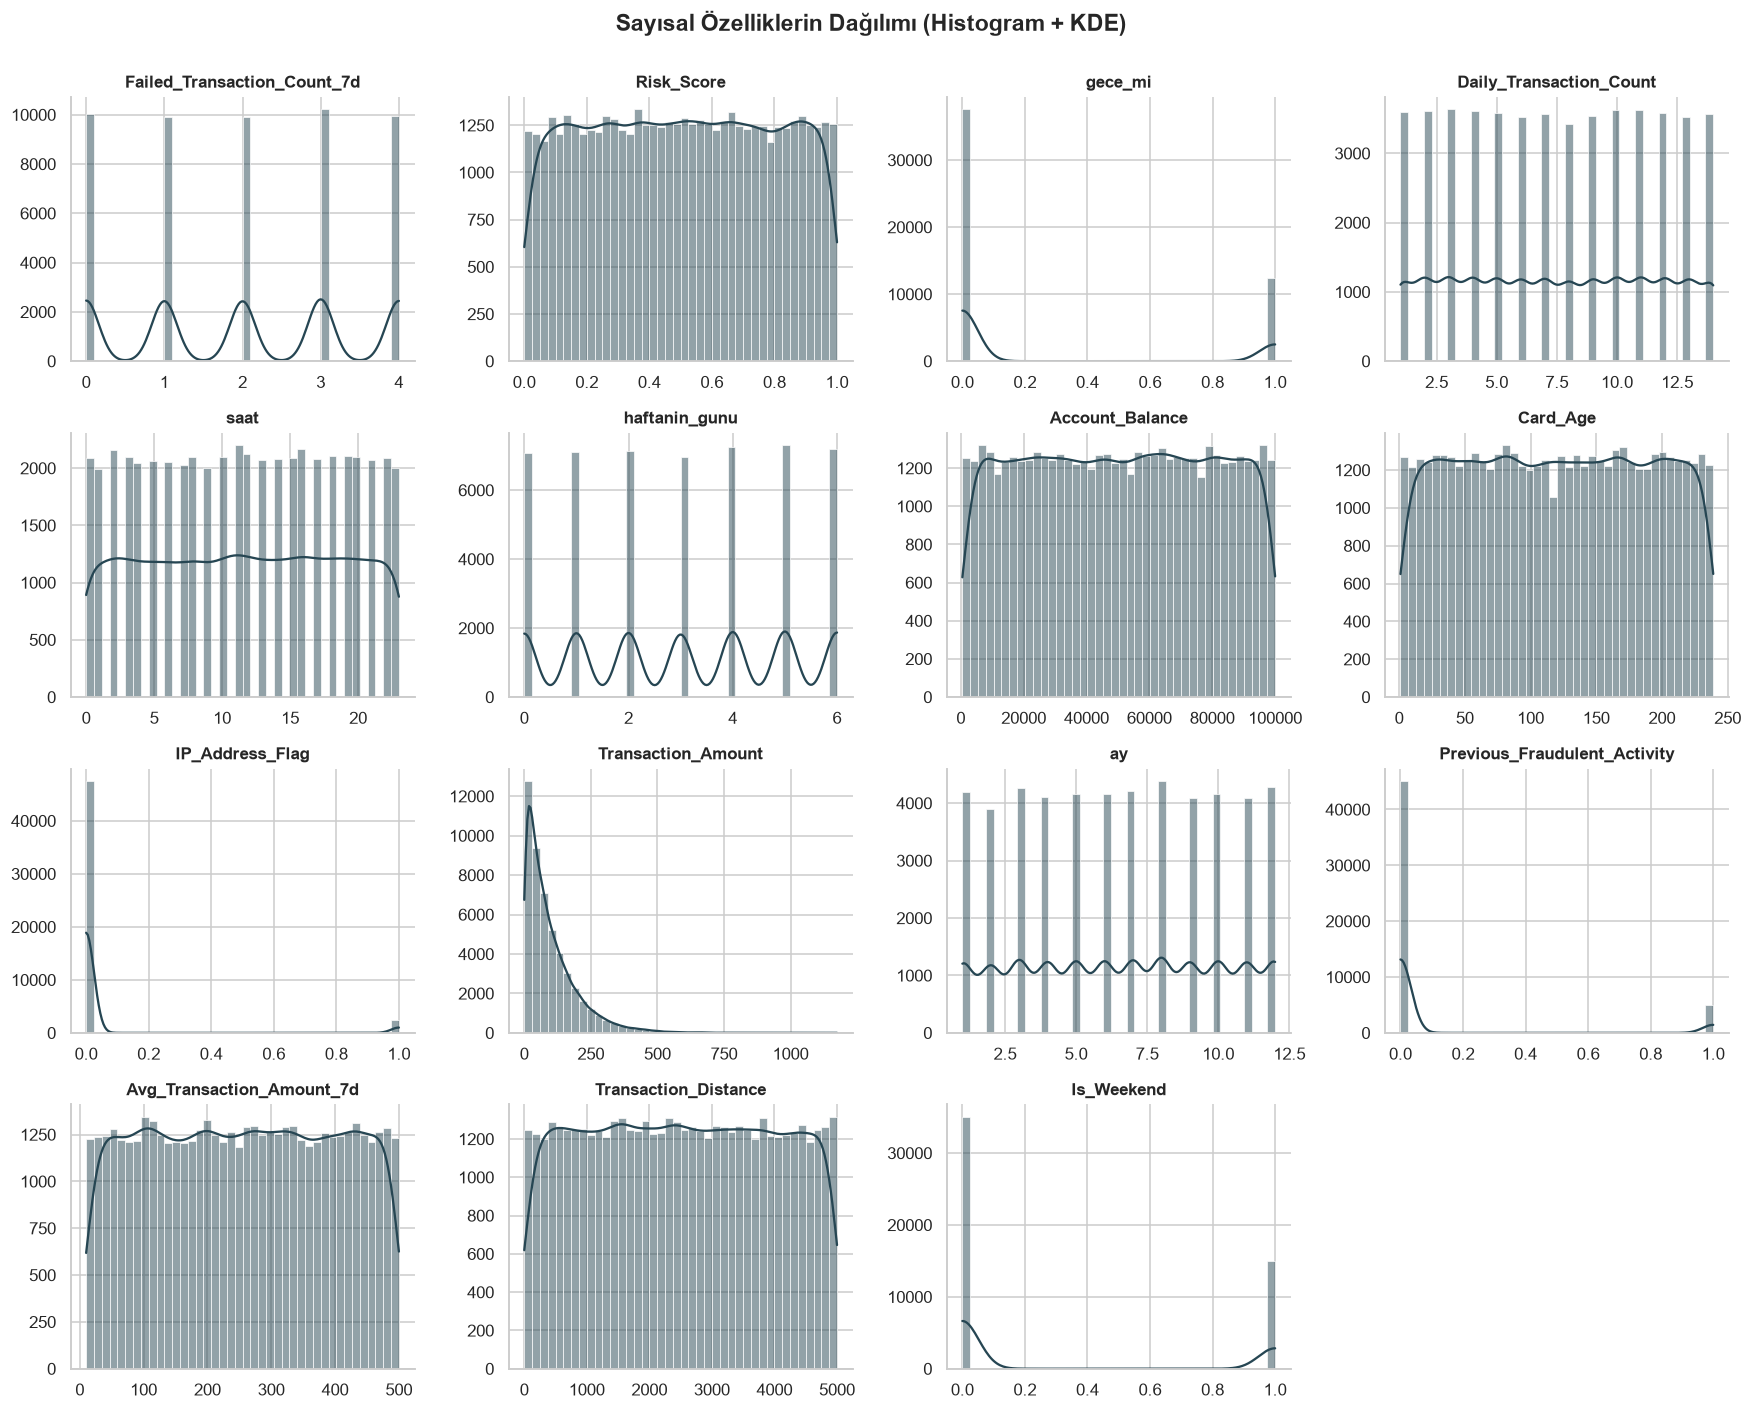

In [12]:
def grid_ciz(cols, ciz_fonksiyonu, baslik, ncol=4, h=3.2):
    """cols listesi için ncol sütunlu bir grid açar ve her hücreyi ciz_fonksiyonu(ax, col) ile doldurur."""
    n = len(cols)
    nrow = math.ceil(n / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 4, nrow * h))
    axes = np.array(axes).ravel()
    for ax, c in zip(axes, cols):
        ciz_fonksiyonu(ax, c)
        ax.set_title(str(c), fontsize=11)
        ax.set_xlabel(""); ax.set_ylabel("")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(baslik, fontsize=15, fontweight="bold", y=1.0)
    plt.tight_layout(); plt.show()


# 6a) Genel histogram + KDE
grid_ciz(gosterilecek,
         lambda ax, c: sns.histplot(df_s[c].dropna(), bins=40, kde=True, color="#264653", ax=ax),
         "Sayısal Özelliklerin Dağılımı (Histogram + KDE)")

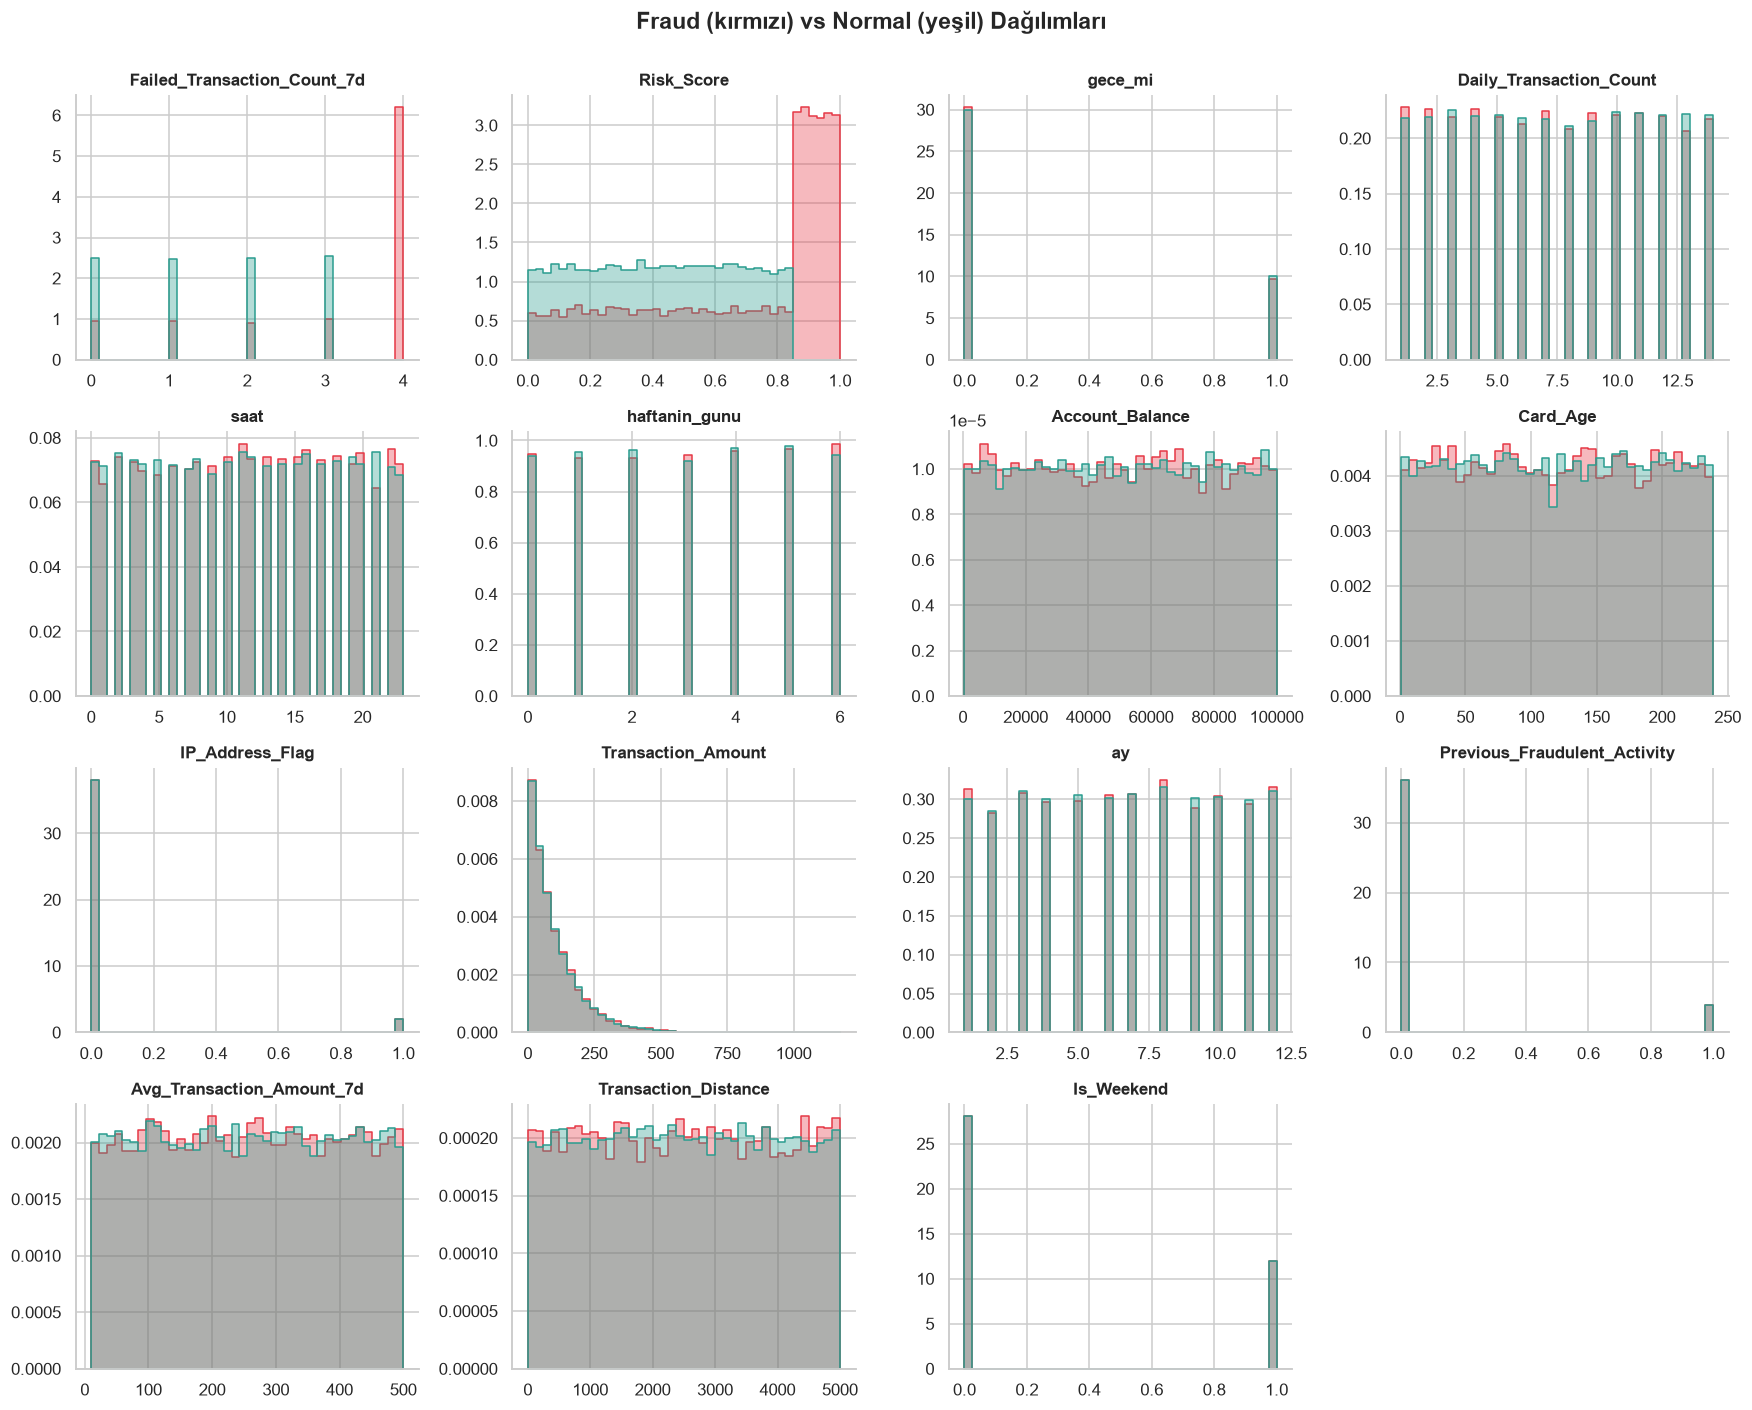

In [13]:
# 6b) Fraud vs Normal histogramı (stat='density' + common_norm=False → her grup kendi içinde normalize)
def hist_sinif(ax, c):
    sns.histplot(data=df_s, x=c, hue=T, bins=40, stat="density", common_norm=False,
                 element="step", palette=PAL, alpha=0.35, ax=ax, legend=False)

grid_ciz(gosterilecek, hist_sinif,
         "Fraud (kırmızı) vs Normal (yeşil) Dağılımları")

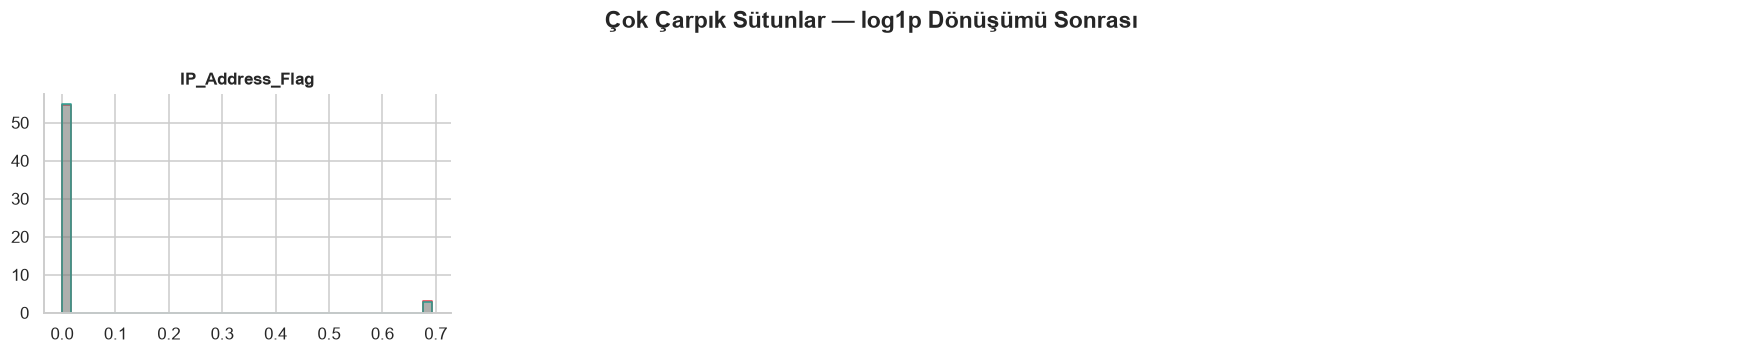

In [14]:
# 6c) Çok çarpık (skew > 3) ve negatif olmayan sütunlar için log1p dönüşümlü histogram.
#     Para tutarı gibi sütunlarda asıl şekil ancak log ölçekte görünür.
carpik = [c for c in sayisal if abs(df[c].skew()) > 3 and df[c].min() >= 0][:8]
if carpik:
    def hist_log(ax, c):
        sns.histplot(data=df_s.assign(_x=np.log1p(df_s[c])), x="_x", hue=T, bins=40, stat="density",
                     common_norm=False, element="step", palette=PAL, alpha=0.35, ax=ax, legend=False)
    grid_ciz(carpik, hist_log, "Çok Çarpık Sütunlar — log1p Dönüşümü Sonrası")
else:
    print("Çok çarpık sütun yok, log dönüşümü gerekmiyor.")

## 7. Boxplot (Kutu Grafiği) 📦

Boxplot bir sütunun **medyanını, çeyreklerini ve uç değerlerini** tek şekilde gösterir:
- Kutunun ortasındaki çizgi = **medyan**, kutunun kenarları = **%25 ve %75**
- Bıyıklar = normal aralık (1.5 × IQR), dışındaki noktalar = **aykırı değer (outlier)**

Burada her sütun için **Normal ve Fraud kutuları yan yana**. Kutular birbirinden farklı yerdeyse özellik ayırt edicidir.
Çok çarpık sütunlarda eksen `symlog` ölçeğine alındı ki kutular görünsün.

> Dikkat: Fraud'da outlier olması **normaldir ve bilgi taşır**. Fraud tespitinde aykırı değerleri silmeyiz!

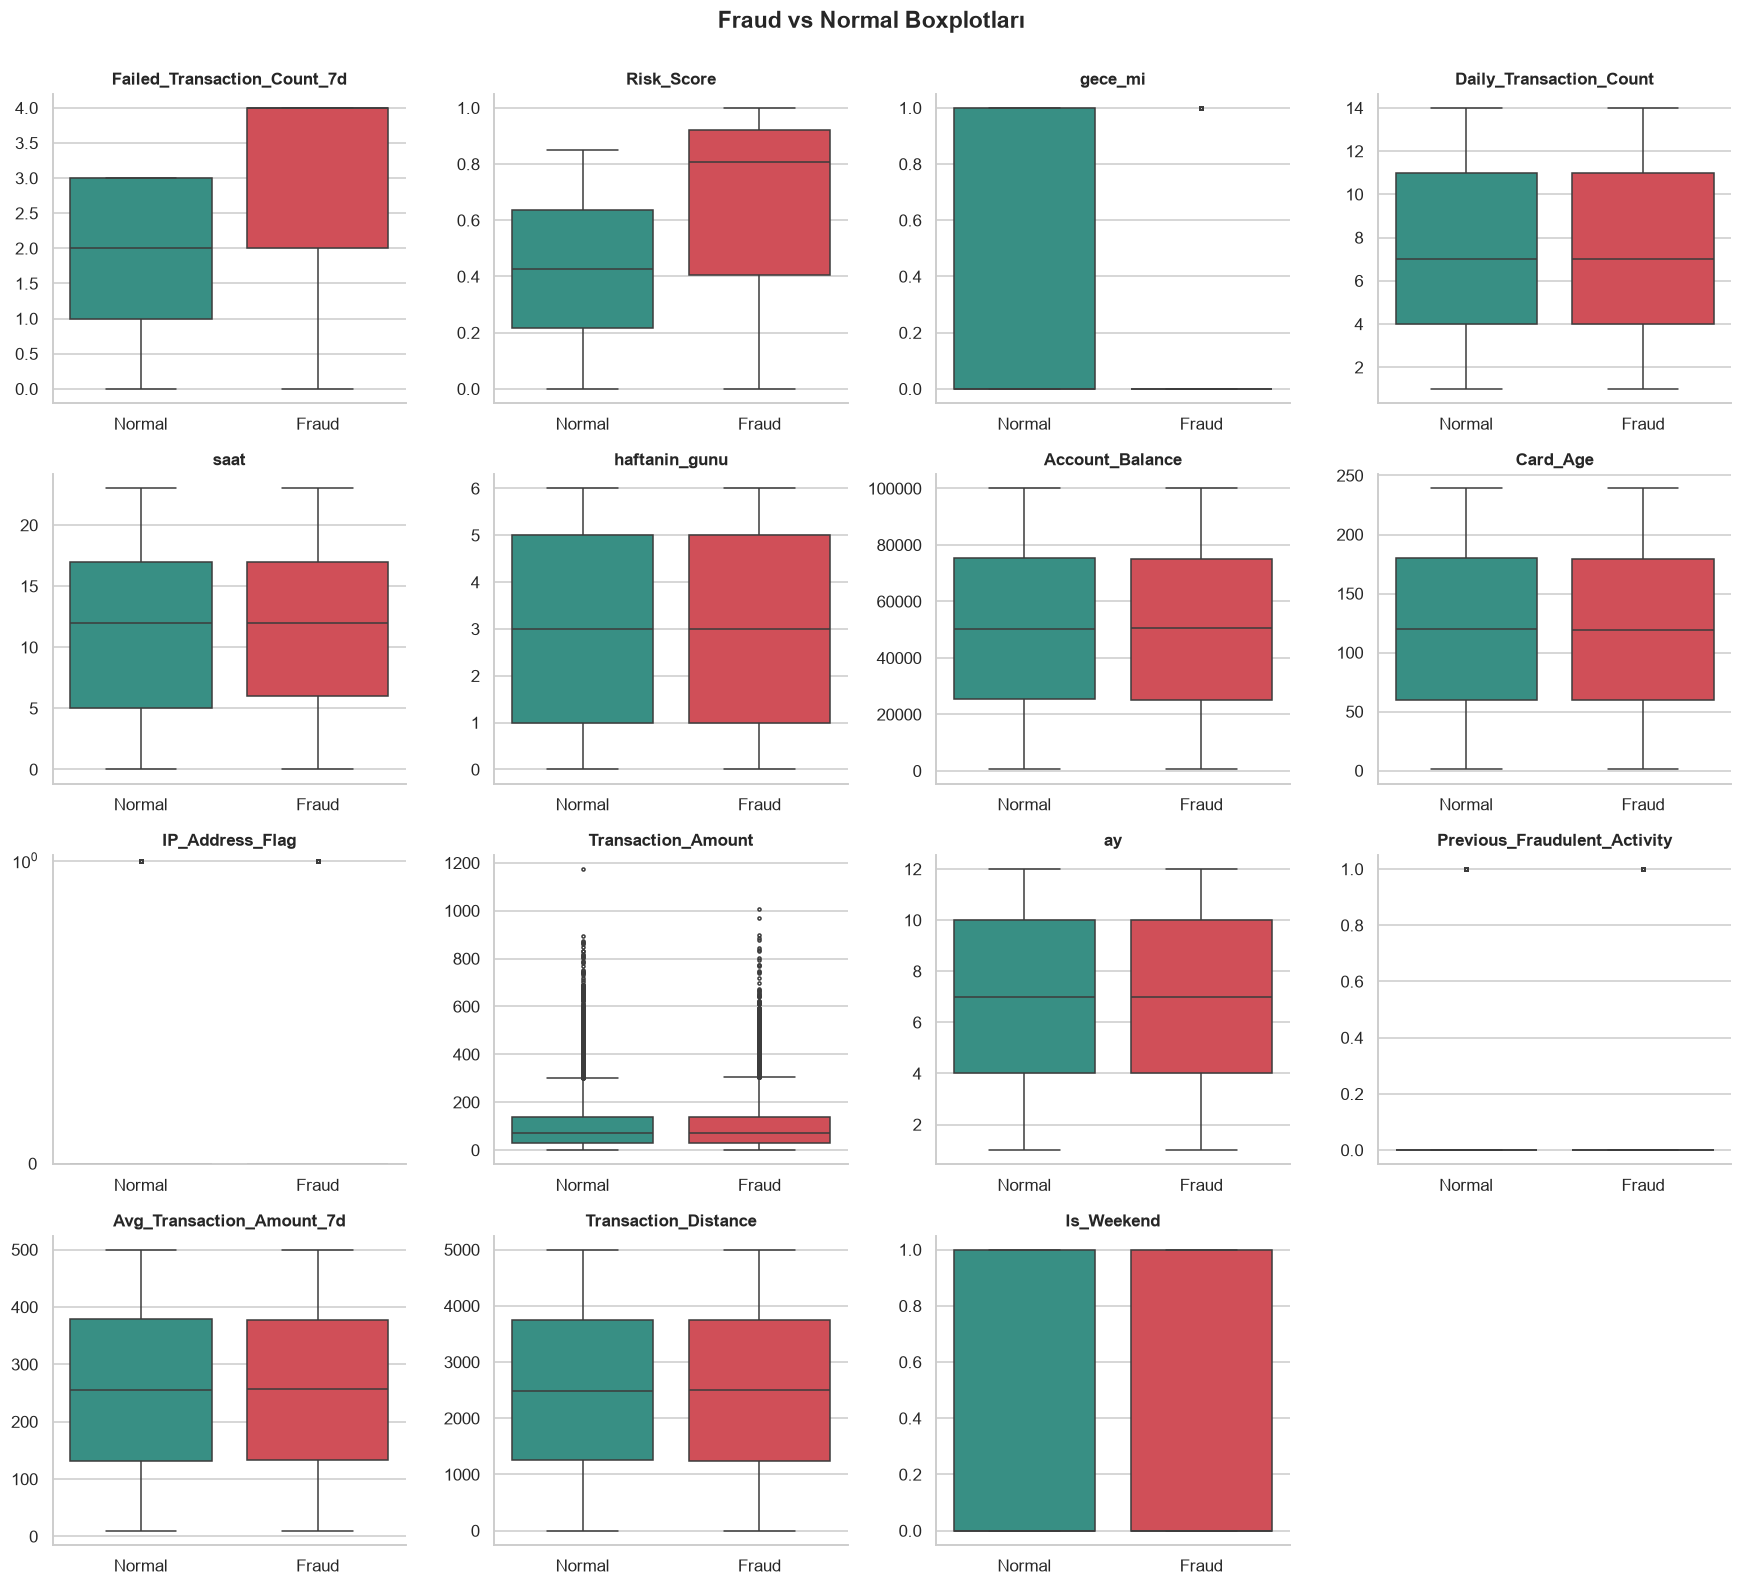

In [15]:
def box_sinif(ax, c):
    sns.boxplot(data=df_s, x=T, y=c, hue=T, palette=PAL, legend=False, fliersize=2, linewidth=1, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Fraud"])
    if abs(df[c].skew()) > 3:
        ax.set_yscale("symlog", linthresh=1)
        if df[c].min() >= 0:          # negatif değer yoksa eksenin negatif tarafını kes (boş yer kalmasın)
            ax.set_ylim(bottom=0)

grid_ciz(gosterilecek, box_sinif, "Fraud vs Normal Boxplotları", h=3.6)

In [16]:
# Aykırı değer oranı tablosu (IQR yöntemi): hangi sütunlarda fraud, normalden çok daha fazla uç değer üretiyor?
def iqr_oran(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    if iqr == 0:
        return 0.0
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

ay = pd.DataFrame({
    "genel_%":  [iqr_oran(df[c].dropna()) for c in sayisal],
    "normal_%": [iqr_oran(df.loc[df[T] == 0, c].dropna()) for c in sayisal],
    "fraud_%":  [iqr_oran(df.loc[df[T] == 1, c].dropna()) for c in sayisal],
}, index=sayisal)
display(ay.sort_values("fraud_%", ascending=False).head(15))

,genel_%,normal_%,fraud_%
Transaction_Amount,4.5200,4.5413,4.4937
Account_Balance,0.0000,0.0000,0.0000
IP_Address_Flag,0.0000,0.0000,0.0000
Previous_Fraudulent_Activity,0.0000,0.0000,0.0000
Daily_Transaction_Count,0.0000,0.0000,0.0000
Avg_Transaction_Amount_7d,0.0000,0.0000,0.0000
Failed_Transaction_Count_7d,0.0000,0.0000,0.0000
Card_Age,0.0000,0.0000,0.0000
Transaction_Distance,0.0000,0.0000,0.0000
Risk_Score,0.0000,0.0000,0.0000


## 8. Scatterplot (Saçılım Grafiği) 🔵🔴

Scatterplot **iki sayısal özelliği** aynı anda gösterir; her nokta bir işlem. Fraud'ları kırmızı, normalleri yeşil çizdim.

**Ne arıyoruz?** Kırmızı noktalar yeşil bulutun dışında ayrı bir bölgede toplanıyor mu? Toplanıyorsa bu iki özellik birlikte fraud'u ayırıyor demektir.
Hedefle en ilişkili ilk 4 özelliğin ikili kombinasyonlarını çiziyorum.

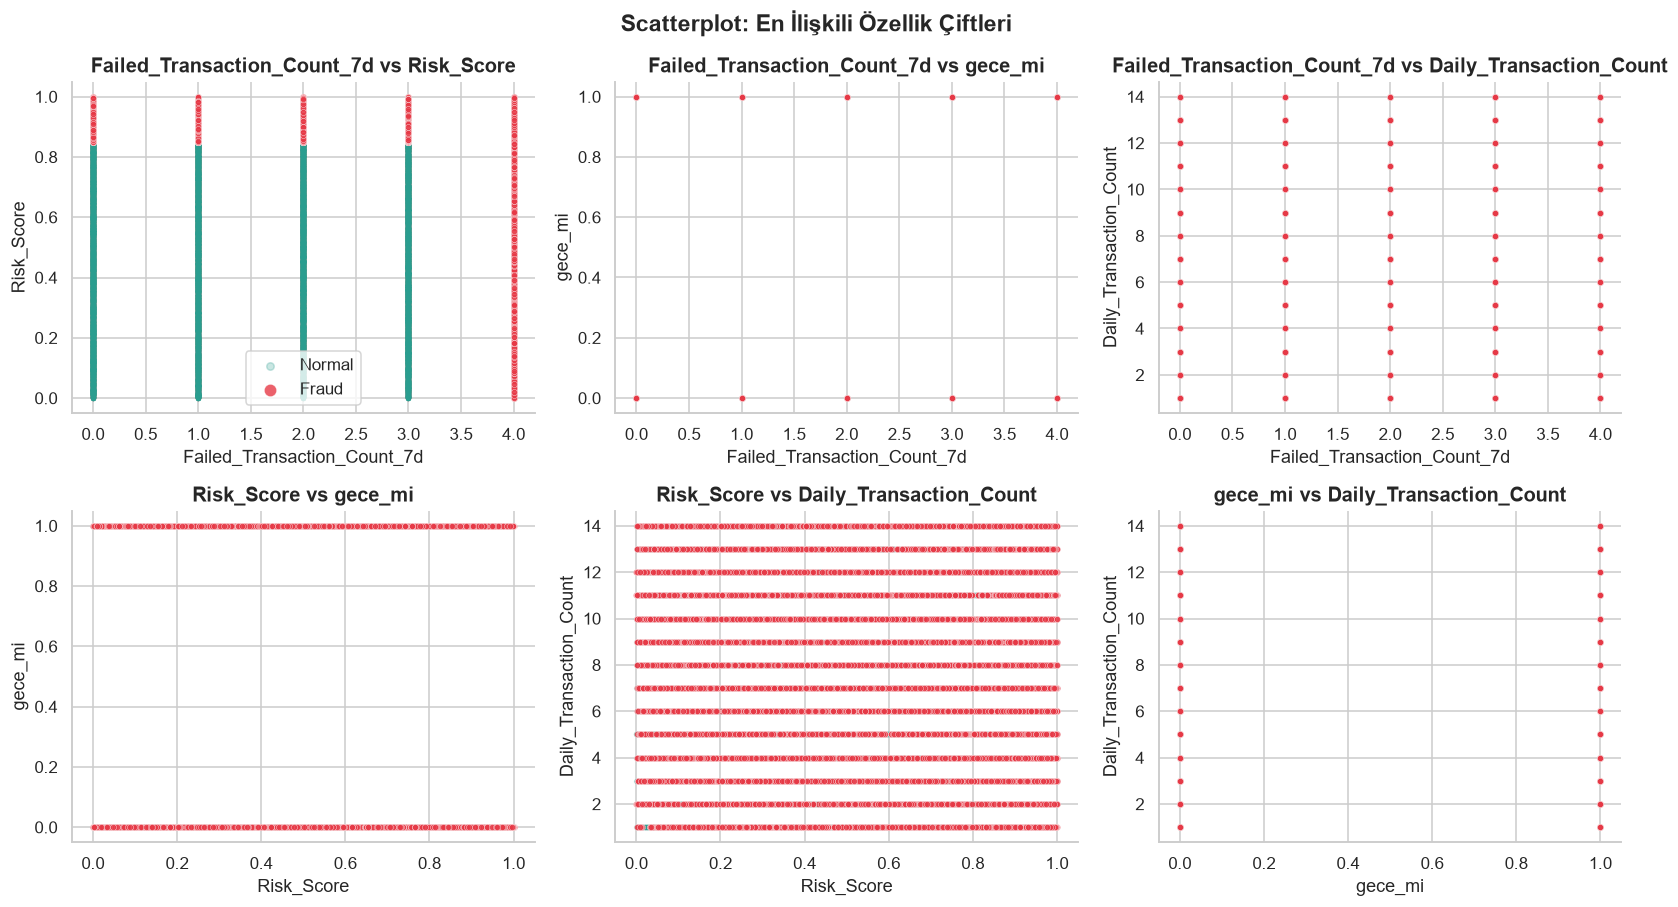

In [17]:
en_iyi4 = oncelikli[:4]
ciftler = [(a, b) for i, a in enumerate(en_iyi4) for b in en_iyi4[i + 1:]]

if len(ciftler) == 0:
    print("Scatter için en az 2 sayısal özellik gerekli.")
else:
    ncol = 3
    nrow = math.ceil(len(ciftler) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 5, nrow * 4.2))
    axes = np.array(axes).ravel()
    normal = df_s[df_s[T] == 0]; fraud = df_s[df_s[T] == 1]
    for ax, (a, b) in zip(axes, ciftler):
        # önce normaller (soluk), üstüne fraud'lar (belirgin) → fraud'lar görünür kalır
        ax.scatter(normal[a], normal[b], s=6, alpha=0.25, c=PAL[0], label="Normal")
        ax.scatter(fraud[a], fraud[b], s=16, alpha=0.8, c=PAL[1], label="Fraud", edgecolors="white", linewidths=0.3)
        ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"{a} vs {b}")
    for ax in axes[len(ciftler):]:
        ax.axis("off")
    axes[0].legend(markerscale=2)
    fig.suptitle("Scatterplot: En İlişkili Özellik Çiftleri", fontsize=15, fontweight="bold")
    plt.tight_layout(); plt.show()

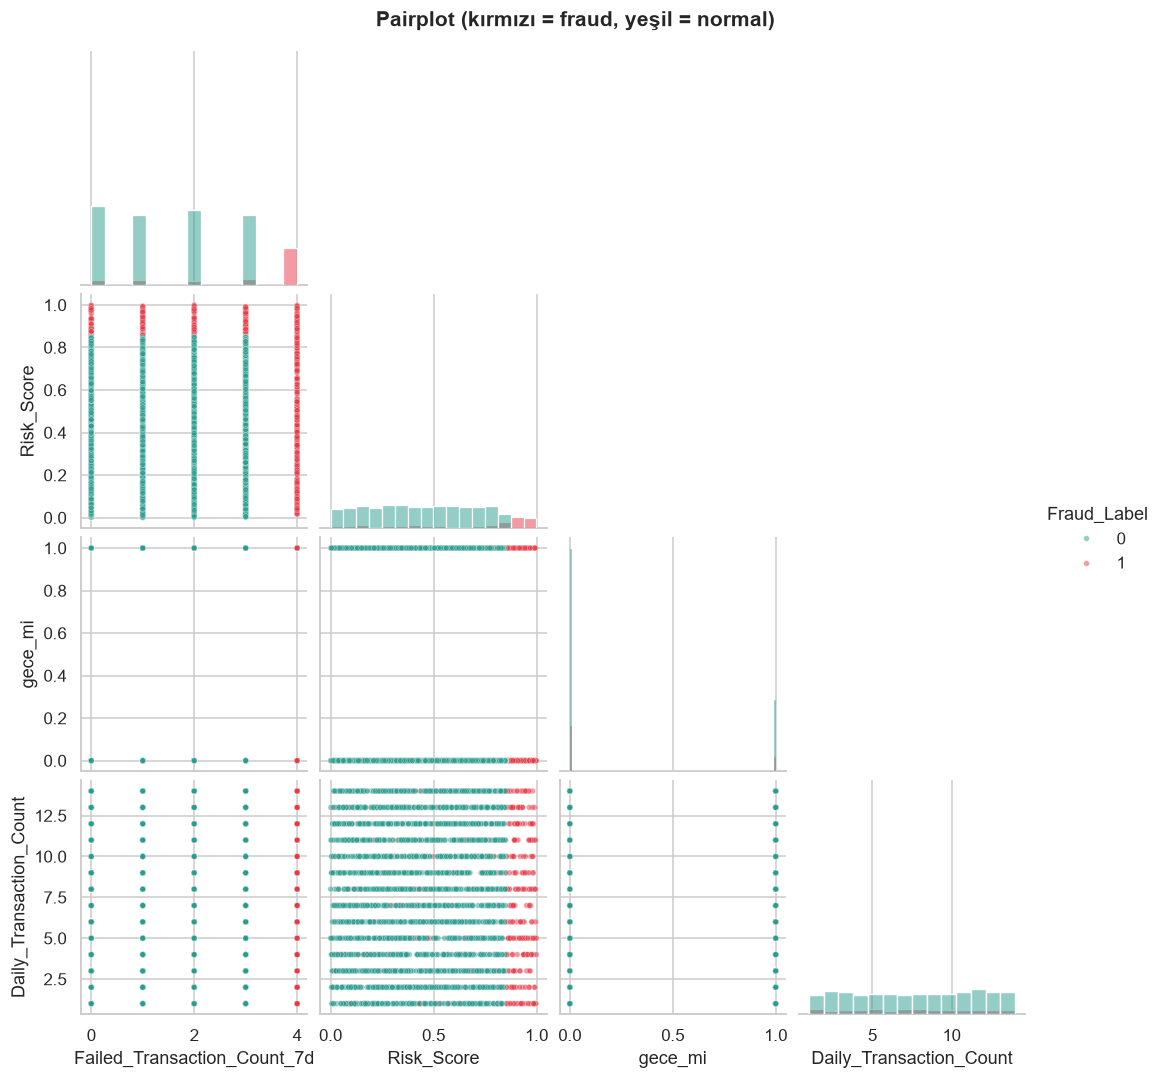

In [18]:
# Pairplot: aynı 4 özelliğin tüm ikili ilişkileri + köşegende dağılımlar (küçük örnek, hızlı olsun)
if len(en_iyi4) >= 2:
    f = df[df[T] == 1]; n = df[df[T] == 0]
    pp = pd.concat([f.sample(min(len(f), 500), random_state=RANDOM_STATE),
                    n.sample(min(len(n), 2500), random_state=RANDOM_STATE)])
    g = sns.pairplot(pp, vars=en_iyi4, hue=T, palette=PAL, corner=True, diag_kind="hist",
                     plot_kws=dict(s=14, alpha=0.5), height=2.4)
    g.fig.suptitle("Pairplot (kırmızı = fraud, yeşil = normal)", y=1.02, fontsize=14, fontweight="bold")
    plt.show()

## 9. Korelasyon Analizi 🔗

**Korelasyon** iki sütunun birlikte ne kadar hareket ettiğini ölçer (-1 ile +1 arası).
İki tür bakıyoruz:
1. **Hedefle korelasyon:** hangi özellik fraud ile ilişkili? (Pearson, 0/1 hedefle buna *point-biserial* denir)
2. **Özellikler arası korelasyon:** iki özellik birbirinin kopyasıysa (|r| > 0.95) birini atarız. Aynı bilgiyi iki kez vermek modele fayda sağlamaz.

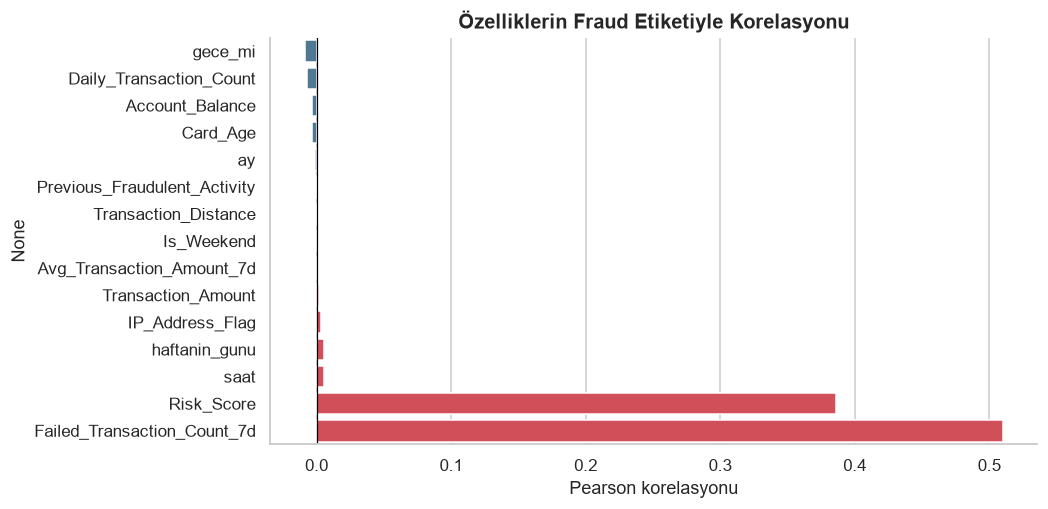

In [19]:
# 9a) Hedefle korelasyon (işaretli): pozitif = arttıkça fraud olasılığı artar
kor_h = df[sayisal].corrwith(df[T]).dropna().sort_values()
en_uc = pd.concat([kor_h.head(12), kor_h.tail(12)]).drop_duplicates()
plt.figure(figsize=(9, max(4, len(en_uc) * 0.32)))
sns.barplot(x=en_uc.values, y=en_uc.index, palette=["#e63946" if v > 0 else "#457b9d" for v in en_uc.values])
plt.axvline(0, color="black", lw=0.8)
plt.title("Özelliklerin Fraud Etiketiyle Korelasyonu"); plt.xlabel("Pearson korelasyonu")
plt.show()

# Çok yüksek korelasyon = hedef sızıntısı şüphesi
supheli = kor_h[kor_h.abs() > 0.9]
if len(supheli):
    print("🚨 UYARI: Hedefle |r|>0.9 olan sütunlar (sızıntı olabilir, gerçek hayatta bu bilgi işlem anında bilinmez!):")
    print(supheli)

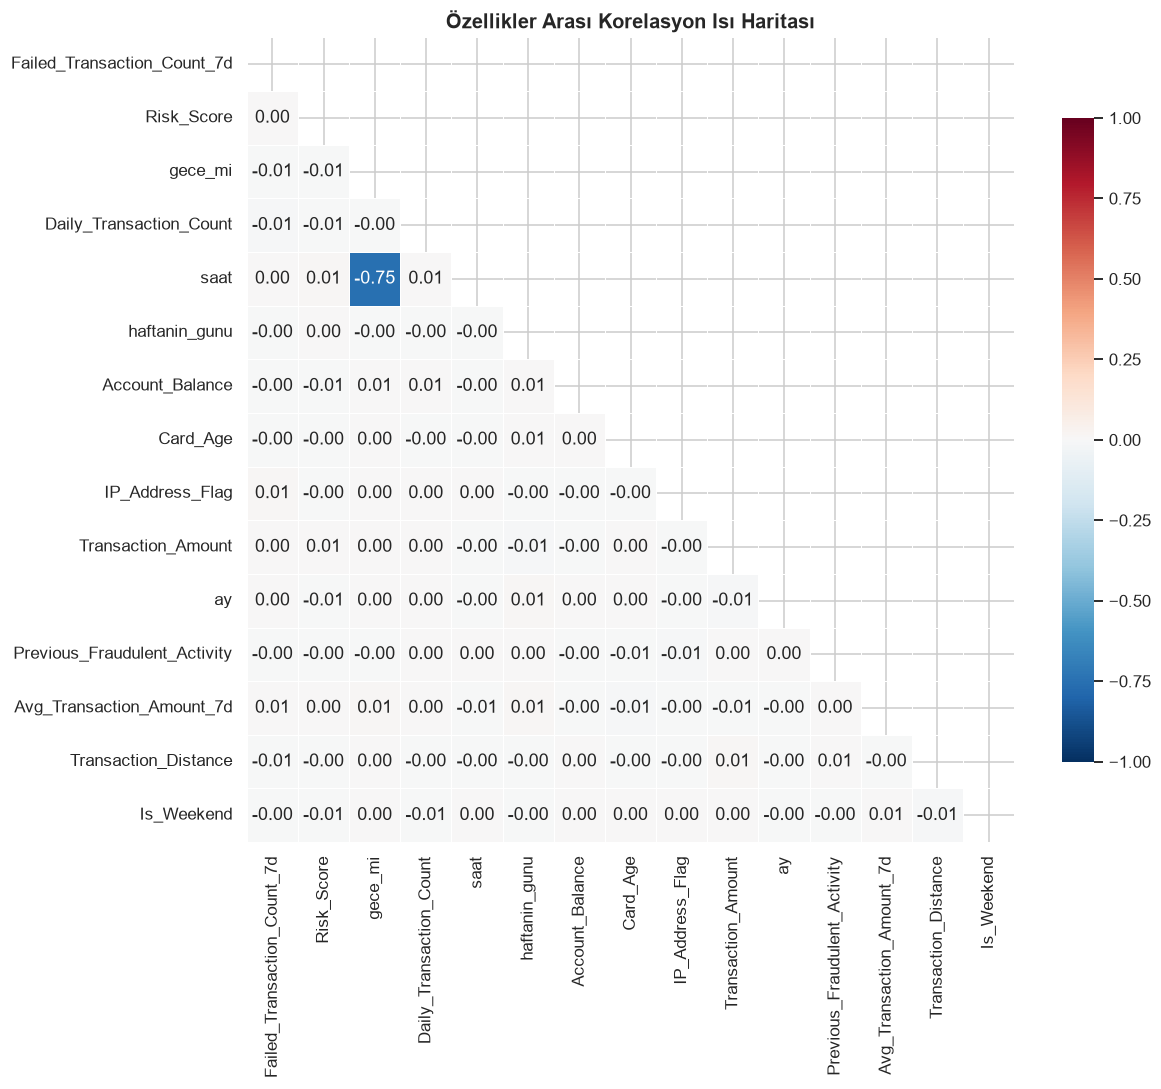

In [20]:
# 9b) Özellikler arası korelasyon ısı haritası (en fazla 25 sütun: hedefle en ilişkili olanlar)
sec = oncelikli[:25]
if len(sec) >= 2:
    kor = df_s[sec].corr()
    maske = np.triu(np.ones_like(kor, dtype=bool))  # üst üçgeni gizle (simetrik, tekrar eder)
    plt.figure(figsize=(min(14, 3 + len(sec) * 0.55), min(12, 2 + len(sec) * 0.5)))
    sns.heatmap(kor, mask=maske, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                annot=len(sec) <= 15, fmt=".2f", linewidths=0.4, cbar_kws={"shrink": 0.8})
    plt.title("Özellikler Arası Korelasyon Isı Haritası"); plt.show()

## 9c. 🚨 Sızıntı / Aşırı Güçlü Özellik Kontrolü
Bu bölüm çok önemli. Bir özellik fraud'u **tek başına neredeyse mükemmel** ayırıyorsa iki ihtimal vardır:
1. Etiket o özellikten **kural olarak** üretilmiş (sentetik veri setlerinde sık görülür) → model "kural ezberler", gerçek hayatta işe yaramaz
2. Özellik fraud **olduktan sonra** oluşuyor (sızıntı) → işlem anında bilinmez

İki kontrol yapıyorum:
- **Tek özellik AUC'si:** özellik tek başına fraud/normal'i ne kadar ayırıyor? (0.5 = hiç, 1.0 = mükemmel). **0.90 üstü şüphelidir.**
- **"Saf değer" kontrolü:** bir değerin geçtiği satırların **%99+'ı fraud** mu? (örn. `Failed_Transaction_Count_7d = 4` olan herkes fraud)

Bunlar otomatik atılmaz; sen karar verirsin (`EKSTRA_ATILACAK` listesi). Ama raporunda mutlaka yorumla!

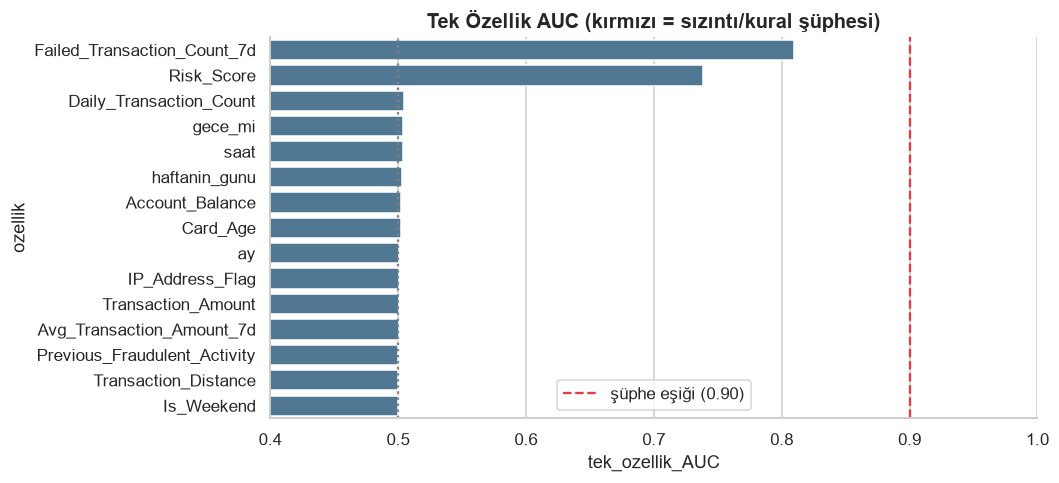

✅ Tek başına aşırı güçlü özellik yok (AUC > 0.90 olan sütun bulunmadı).


In [21]:
from sklearn.metrics import roc_auc_score

# 1) Tek özellik AUC'si (yön önemsiz → max(auc, 1-auc))
auc_liste = []
for c in sayisal:
    m = df[c].notna()
    if df.loc[m, c].nunique() < 2 or df.loc[m, T].nunique() < 2:
        continue
    a = roc_auc_score(df.loc[m, T], df.loc[m, c])
    auc_liste.append((c, max(a, 1 - a)))
auc_tablo = pd.DataFrame(auc_liste, columns=["ozellik", "tek_ozellik_AUC"]).sort_values("tek_ozellik_AUC", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, max(4, len(auc_tablo) * 0.3)))
renk = ["#e63946" if v > 0.90 else "#457b9d" for v in auc_tablo["tek_ozellik_AUC"]]
sns.barplot(data=auc_tablo, x="tek_ozellik_AUC", y="ozellik", palette=renk)
plt.axvline(0.5, color="gray", ls=":"); plt.axvline(0.90, color="#e63946", ls="--", label="şüphe eşiği (0.90)")
plt.xlim(0.4, 1.0); plt.legend(); plt.title("Tek Özellik AUC (kırmızı = sızıntı/kural şüphesi)"); plt.show()

supheli_auc = auc_tablo[auc_tablo["tek_ozellik_AUC"] > 0.90]
if len(supheli_auc):
    print("🚨 Tek başına çok güçlü özellikler:")
    display(supheli_auc)
else:
    print("✅ Tek başına aşırı güçlü özellik yok (AUC > 0.90 olan sütun bulunmadı).")

In [22]:
# 2) "Saf değer" kontrolü: bir değerin geçtiği satırların >= %99'u fraud mu?
#    (Fraud oranı yüksek veride, hiç fraud içermeyen saf değerlere de bakarız)
temel_oran = df[T].mean()
saf = []
for c in sayisal + kategorik:
    if df[c].nunique() > 30:          # sürekli sütunlarda tek tek değere bakmak anlamsız
        continue
    g = df.groupby(c)[T].agg(["mean", "count"])
    for deger, satir in g.iterrows():
        if satir["count"] < 0.01 * len(df):      # çok az satırı olan değerler tesadüf olabilir
            continue
        if satir["mean"] >= 0.99 or (temel_oran > 0.05 and satir["mean"] <= 0.01):
            saf.append((c, deger, int(satir["count"]), satir["mean"] * 100))

if saf:
    print("🚨 Fraud'u (veya normali) neredeyse %100 belirleyen değerler:")
    display(pd.DataFrame(saf, columns=["ozellik", "deger", "satir_sayisi", "fraud_%"]))
    print("→ Bu özellikler modeli kolayca 'kandırır'. Gerçek hayatta bu bilgi etiketle aynı anda mı oluşuyor, kontrol et.")
else:
    print("✅ Saf değer bulunmadı.")

🚨 Fraud'u (veya normali) neredeyse %100 belirleyen değerler:


,ozellik,deger,satir_sayisi,fraud_%
0,Failed_Transaction_Count_7d,4,9954,100.0000


→ Bu özellikler modeli kolayca 'kandırır'. Gerçek hayatta bu bilgi etiketle aynı anda mı oluşuyor, kontrol et.


## 10. Kategorik Değişken Analizi 🏷️

Her kategorik sütunda **kategori başına fraud oranını** çiziyorum (çubuk yüksekliği = o kategorideki işlemlerin yüzde kaçı fraud).
Üstündeki sayı o kategorideki toplam işlem sayısıdır; küçük gruplardaki yüksek oran yanıltıcı olabilir, bu yüzden sayıya da bak.

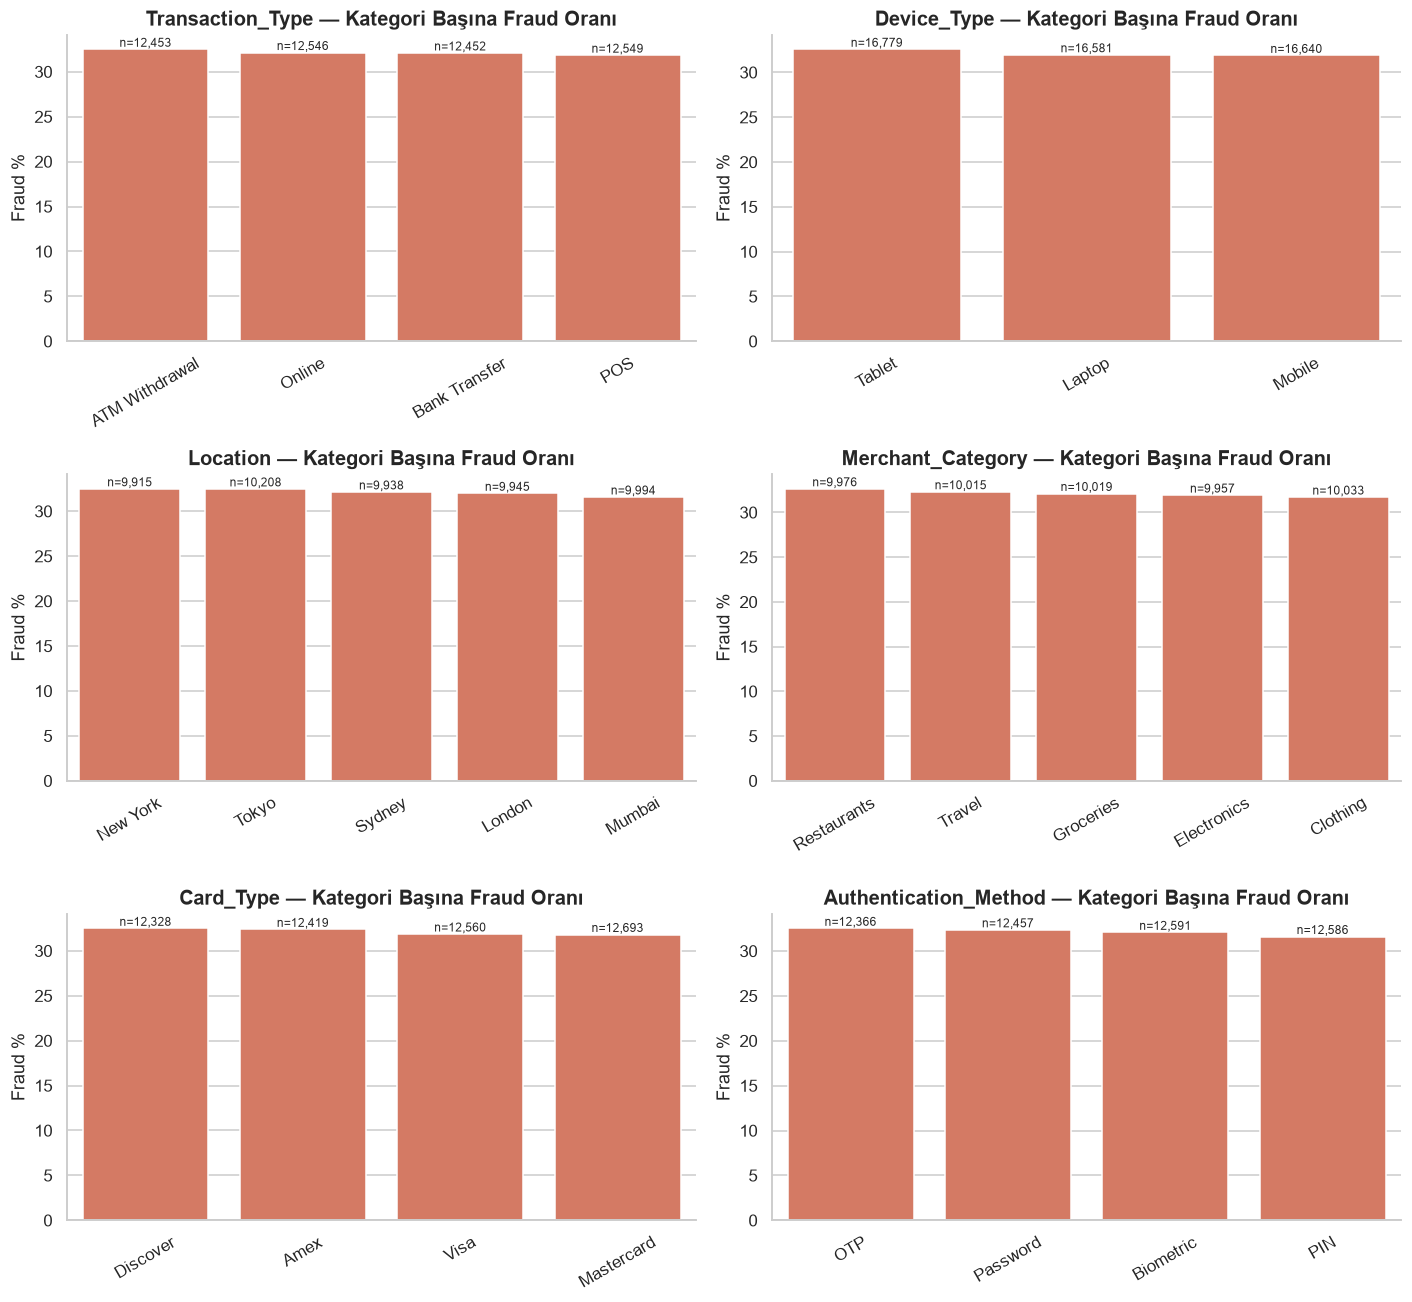

In [23]:
kat_cizilecek = [c for c in kategorik if df[c].nunique() <= 30][:6]
if not kat_cizilecek:
    print("Grafikle gösterilecek kategorik sütun yok (ya hiç yok ya da çok fazla farklı değer içeriyor).")
else:
    ncol = 2; nrow = math.ceil(len(kat_cizilecek) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(13, nrow * 4))
    axes = np.array(axes).ravel()
    for ax, c in zip(axes, kat_cizilecek):
        g = df.groupby(c)[T].agg(["mean", "count"]).sort_values("mean", ascending=False).head(15)
        sns.barplot(x=g.index.astype(str), y=g["mean"] * 100, color="#e76f51", ax=ax)
        for i, (oran, adet) in enumerate(zip(g["mean"] * 100, g["count"])):
            ax.text(i, oran, f"n={adet:,}", ha="center", va="bottom", fontsize=8)
        ax.set_title(f"{c} — Kategori Başına Fraud Oranı"); ax.set_ylabel("Fraud %"); ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)
    for ax in axes[len(kat_cizilecek):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 11. Zaman Analizi ⏰
Fraud genelde belli saatlerde (gece) yoğunlaşır. Veride zaman sütunu varsa (`Time`, `step`, tarih sütunu) fraud oranını zamana göre çiziyorum.
Zaman sütunu yoksa bu hücre atlanır.

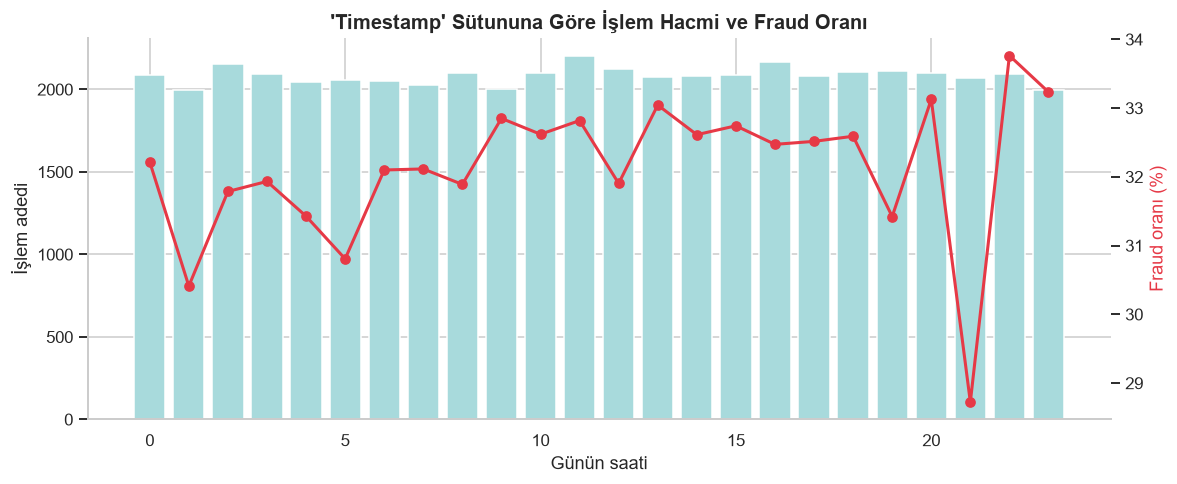

In [24]:
kucuk_ad = {str(c).lower(): c for c in df.columns}
zaman_adi = next((kucuk_ad[a] for a in ["time", "step", "timestamp", "date", "trans_date_trans_time", "transaction_date"] if a in kucuk_ad), None)

if zaman_adi is None:
    print("Zaman sütunu bulunamadı, atlandı.")
else:
    z = df[zaman_adi]
    if pd.api.types.is_numeric_dtype(z):
        # Sayısal zaman: 48 eşit parçaya böl, her parçada işlem adedi ve fraud oranı
        parca = pd.cut(z, bins=48)
        g = df.groupby(parca, observed=True)[T].agg(["count", "mean"])
        x = np.arange(len(g)); xetiket = "Zaman parçası (başlangıçtan sona)"
    else:
        dt = pd.to_datetime(z, errors="coerce")
        if dt.notna().mean() < 0.9:
            g = None; print("Zaman sütunu tarihe çevrilemedi, atlandı.")
        else:
            g = df.groupby(dt.dt.hour)[T].agg(["count", "mean"]); x = g.index.values; xetiket = "Günün saati"
    if g is not None:
        fig, ax1 = plt.subplots(figsize=(12, 4.5))
        ax1.bar(x, g["count"], color="#a8dadc", label="İşlem adedi")
        ax1.set_ylabel("İşlem adedi"); ax1.set_xlabel(xetiket)
        ax2 = ax1.twinx()
        ax2.plot(x, g["mean"] * 100, color=PAL[1], marker="o", lw=2, label="Fraud %")
        ax2.set_ylabel("Fraud oranı (%)", color=PAL[1]); ax2.grid(False)
        plt.title(f"'{zaman_adi}' Sütununa Göre İşlem Hacmi ve Fraud Oranı"); plt.show()

## 12. EDA'dan Çıkan Notlar (kendi yorumunu buraya yaz ✍️)
Rapor/sunum için şunları doldur:
- Sınıf dengesizliği oranı: ?
- Fraud'u en iyi ayıran 3 özellik: ?
- Çok çarpık/aykırı değerli sütunlar: ?
- Eksik değer var mı, nasıl dolduracağız: ?
- Fraud'un yoğunlaştığı kategori/zaman: ?

---
# 🛠️ BÖLÜM 2 — Ön İşleme Hattı

Sıra: **Temizlik → Özellik Üretimi → Train/Test Ayırma → Eksik Doldurma → Encoding → Ölçekleme → Özellik Seçimi**

> **Altın kural (veri sızıntısı):** Ortalama, medyan, ölçekleyici, frekans tablosu gibi her şeyi **sadece train verisinden öğrenip** test'e uygularız.
> Bu yüzden train/test ayırmayı bu adımların **önüne** koydum. Satır bazlı (başka satıra bakmayan) özellik üretimini ayırmadan önce yapmak güvenlidir.
> (Bu bir model eğitmek değildir; sadece veriyi bölüyoruz.)

## 13. Temizlik: ID, Sızıntı ve Sabit Sütunları Atma
- **ID benzeri sütunlar** → model ezber yapar, atılır
- **Sızıntı (leakage) sütunları** → hedefle neredeyse aynı bilgiyi taşıyan veya fraud'dan *sonra* oluşan sütunlar (örn. PaySim'deki `isFlaggedFraud`). Gerçek hayatta işlem anında bilinmez, tutarsak model kopya çeker.
- **Sabit sütunlar** → her satırda aynı değer, bilgi taşımaz
- **Tekrar eden satırlar** → silinir

In [25]:
SIZINTI_ADLARI = ["isflaggedfraud"]    # ✏️ veri setine göre buraya sızıntı sütunu adlarını ekleyebilirsin (küçük harfle)

atilacak = []
for c in df.columns:
    if c == T:
        continue
    if c in zaman_cols:
        atilacak.append((c, "ham zaman sütunu (saat/gün/ay özelliklerine ayrıldı)"))
    elif c in EKSTRA_ATILACAK:
        atilacak.append((c, "senin EKSTRA_ATILACAK listen"))
    elif c in id_benzeri:
        atilacak.append((c, "ID benzeri"))
    elif str(c).lower() in SIZINTI_ADLARI:
        atilacak.append((c, "hedef sızıntısı"))
    elif df[c].nunique(dropna=False) <= 1:
        atilacak.append((c, "sabit sütun"))

# Hedefle |r| > 0.99 olan sayısal sütun da sızıntıdır
for c, r in df[sayisal].corrwith(df[T]).items():
    if abs(r) > 0.99 and c not in [a for a, _ in atilacak]:
        atilacak.append((c, f"hedefle korelasyon {r:.3f} → sızıntı şüphesi"))

for c, neden in atilacak:
    print(f"🗑️  atılıyor: {c:25s} → {neden}")

onceki = len(df)
d = df.drop(columns=[c for c, _ in atilacak]).drop_duplicates().reset_index(drop=True)
print(f"\nTekrar eden {onceki - len(d):,} satır silindi. Kalan: {len(d):,} satır, {d.shape[1]} sütun")

🗑️  atılıyor: Transaction_ID            → ID benzeri
🗑️  atılıyor: User_ID                   → ID benzeri
🗑️  atılıyor: Timestamp                 → ham zaman sütunu (saat/gün/ay özelliklerine ayrıldı)

Tekrar eden 0 satır silindi. Kalan: 50,000 satır, 22 sütun


## 14. Özellik Üretimi (Feature Engineering) 🧪

Ham sütunlardan modelin daha kolay öğrenebileceği yeni sütunlar türetiyorum. Hepsi **satır bazlı**, yani başka satırlara bakmaz (sızıntı riski yok):

| Üretilen özellik | Ne yapar? | Neden işe yarar? |
|---|---|---|
| `*_log` | Tutar/bakiye sütunlarına `log1p` uygular | Çarpık dağılımı simetrikleştirir |
| `saat`, `haftanin_gunu`, `ay`, `gece_mi` | `Timestamp`'ten (EDA bölümünde üretildi) | Fraud belli saat/günlerde artabilir |
| `tutar_ort_orani` | İşlem tutarı / son 7 gün ortalaması | Alışılmadık büyük/küçük harcamayı yakalar |
| `tutar_bakiye_orani` | İşlem tutarı / hesap bakiyesi | Bakiyenin büyük kısmını harcamak şüphelidir |
| `basarisiz_gunluk_orani` | Başarısız deneme / günlük işlem sayısı | Deneme-yanılma saldırıları |
| `uzaklik_kart_yasi_orani` | İşlem mesafesi / kart yaşı | Yeni kartla uzak işlem |
| `gun` | `step` sütunundan gün | Zamana bağlı desen |
| `bakiye_hatasi_gonderen/alici` | Bakiye hareketinin tutarla tutarlı olup olmadığı | Dolandırıcılık işlemlerinde hesap defteri tutarsız çıkar (PaySim tarzı veride çok güçlüdür) |

Veri setinde ilgili sütunlar yoksa o özellik üretilmez (otomatik atlanır).

In [26]:
kucuk = {str(c).lower(): c for c in d.columns}   # küçük harf -> gerçek ad
yeni_ozellikler = []

# 1) Zaman türevleri
if "saat" in d.columns:
    pass   # Zaman özellikleri (saat, haftanin_gunu, ay, gece_mi) yukarıda Timestamp'ten zaten üretildi
elif "time" in kucuk and pd.api.types.is_numeric_dtype(d[kucuk["time"]]):
    # 'Time' saniye cinsindense: saat = (saniye // 3600) % 24
    d["saat"] = (d[kucuk["time"]] // 3600) % 24
    d["gece_mi"] = d["saat"].between(0, 5).astype(int)
    yeni_ozellikler += ["saat", "gece_mi"]
elif "step" in kucuk and pd.api.types.is_numeric_dtype(d[kucuk["step"]]):
    # 'step' saat cinsindense (PaySim): saat = step % 24, gün = step // 24
    d["saat"] = d[kucuk["step"]] % 24
    d["gun"] = d[kucuk["step"]] // 24
    d["gece_mi"] = d["saat"].between(0, 5).astype(int)
    yeni_ozellikler += ["saat", "gun", "gece_mi"]

# 2) Bakiye tutarlılık hatası (PaySim benzeri sütunlar varsa)
a, o, n = kucuk.get("amount"), kucuk.get("oldbalanceorg"), kucuk.get("newbalanceorig")
if a and o and n:
    d["bakiye_hatasi_gonderen"] = d[n] + d[a] - d[o]   # 0 olmalı; değilse tutarsızlık var
    yeni_ozellikler.append("bakiye_hatasi_gonderen")
od, nd = kucuk.get("oldbalancedest"), kucuk.get("newbalancedest")
if a and od and nd:
    d["bakiye_hatasi_alici"] = d[od] + d[a] - d[nd]
    yeni_ozellikler.append("bakiye_hatasi_alici")

# 3) Oran özellikleri (satır bazlı, bu veri setindeki sütun adlarına göre)
t_, av_, bal_ = kucuk.get("transaction_amount"), kucuk.get("avg_transaction_amount_7d"), kucuk.get("account_balance")
if t_ and av_:
    d["tutar_ort_orani"] = d[t_] / (d[av_] + 1)      # işlem tutarı son 7 gün ortalamasının kaç katı? (alışılmadık harcama)
    yeni_ozellikler.append("tutar_ort_orani")
if t_ and bal_:
    d["tutar_bakiye_orani"] = d[t_] / (d[bal_].abs() + 1)   # bakiyenin ne kadarı harcandı?
    yeni_ozellikler.append("tutar_bakiye_orani")
fail_, daily_ = kucuk.get("failed_transaction_count_7d"), kucuk.get("daily_transaction_count")
if fail_ and daily_:
    d["basarisiz_gunluk_orani"] = d[fail_] / (d[daily_] + 1)   # günlük işleme göre başarısız deneme yoğunluğu
    yeni_ozellikler.append("basarisiz_gunluk_orani")
dist_, age_ = kucuk.get("transaction_distance"), kucuk.get("card_age")
if dist_ and age_:
    d["uzaklik_kart_yasi_orani"] = d[dist_] / (d[age_] + 1)    # yeni kartla uzak işlem şüpheli olabilir
    yeni_ozellikler.append("uzaklik_kart_yasi_orani")

# 4) Para/bakiye benzeri sütunlara log1p (negatif olmayanlara)
for c in list(d.columns):
    if c == T or not pd.api.types.is_numeric_dtype(d[c]):
        continue
    if any(k in str(c).lower() for k in ["amount", "amt", "tutar", "balance", "bakiye"]) and d[c].min() >= 0 and not str(c).endswith("_log") and "oran" not in str(c):
        d[f"{c}_log"] = np.log1p(d[c])
        yeni_ozellikler.append(f"{c}_log")

print("Üretilen yeni özellikler:", yeni_ozellikler if yeni_ozellikler else "(bu veri setinde otomatik üretilecek bir şey bulunamadı)")
if yeni_ozellikler:
    print("\nYeni özelliklerin hedefle korelasyonu:")
    display(d[yeni_ozellikler].corrwith(d[T]).sort_values(key=abs, ascending=False).to_frame("korelasyon"))

Üretilen yeni özellikler: ['tutar_ort_orani', 'tutar_bakiye_orani', 'basarisiz_gunluk_orani', 'uzaklik_kart_yasi_orani', 'Transaction_Amount_log', 'Account_Balance_log', 'Avg_Transaction_Amount_7d_log']

Yeni özelliklerin hedefle korelasyonu:


,korelasyon
basarisiz_gunluk_orani,0.3234
uzaklik_kart_yasi_orani,-0.0036
Account_Balance_log,-0.0035
Avg_Transaction_Amount_7d_log,0.0026
tutar_ort_orani,0.0024
tutar_bakiye_orani,0.0010
Transaction_Amount_log,0.0001


## 15. Train / Test Ayırma ✂️
Veriyi %80 eğitim, %20 test olarak bölüyorum. **`stratify=y`** çok önemli: hem train hem test'te fraud oranı aynı kalır
(yoksa test setine hiç fraud düşmeyebilir).

In [27]:
from sklearn.model_selection import train_test_split

X = d.drop(columns=[T]).copy()
y = d[T].copy()

# bool sütunları sayıya çevir (0/1)
for c in X.select_dtypes(include="bool").columns:
    X[c] = X[c].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]:,} satır (fraud oranı %{y_train.mean()*100:.3f})")
print(f"Test : {X_test.shape[0]:,} satır (fraud oranı %{y_test.mean()*100:.3f})")

Train: 40,000 satır (fraud oranı %32.135)
Test : 10,000 satır (fraud oranı %32.130)


## 16. Eksik Değer Doldurma
- Sayısal sütun → **medyan** (ortalamadan farklı olarak uç değerlerden etkilenmez)
- Kategorik sütun → `"bilinmiyor"` etiketi (eksik olmanın kendisi de fraud için ipucu olabilir)

Medyanlar **sadece train'den** hesaplanıp test'e de aynen uygulanır.

In [28]:
sayisal_f = X_train.select_dtypes(include=np.number).columns.tolist()
kat_f = [c for c in X_train.columns if c not in sayisal_f]

medyanlar = X_train[sayisal_f].median()          # sadece train'den öğren
X_train[sayisal_f] = X_train[sayisal_f].fillna(medyanlar)
X_test[sayisal_f] = X_test[sayisal_f].fillna(medyanlar)

for c in kat_f:
    X_train[c] = X_train[c].astype(str).fillna("bilinmiyor")
    X_test[c] = X_test[c].astype(str).fillna("bilinmiyor")

print("Kalan eksik değer (train):", int(X_train.isna().sum().sum()), "| (test):", int(X_test.isna().sum().sum()))

Kalan eksik değer (train): 0 | (test): 0


## 17. Encoding (Kategorik → Sayı) 🔢

Modeller metinle çalışamaz, kategorileri sayıya çevirmeliyiz:

| Yöntem | Ne zaman? | Nasıl çalışır? |
|---|---|---|
| **One-Hot** | Az kategori (≤10) | Her kategori için 0/1 sütunu açar. `drop_first=True` gereksiz bir sütunu atar |
| **Frekans Encoding** | Çok kategori (>10) | Kategoriyi train'deki görülme sıklığıyla değiştirir (yeni bir sütun açmaz, sızıntı yapmaz) |

Test'te train'de hiç görülmemiş bir kategori çıkarsa one-hot'ta tüm sütunlar 0, frekansta 0 olur.

In [29]:
ESIK_ONEHOT = 10
dusuk_kart = [c for c in kat_f if X_train[c].nunique() <= ESIK_ONEHOT]
yuksek_kart = [c for c in kat_f if c not in dusuk_kart]
print("One-Hot uygulanacak:", dusuk_kart)
print("Frekans encoding uygulanacak:", yuksek_kart)

# Frekans encoding: kategorinin train'deki oranı; test'te görülmeyen kategori → 0
for c in yuksek_kart:
    frekans = X_train[c].value_counts(normalize=True)
    X_train[f"{c}_frekans"] = X_train[c].map(frekans).fillna(0)
    X_test[f"{c}_frekans"] = X_test[c].map(frekans).fillna(0)
X_train = X_train.drop(columns=yuksek_kart)
X_test = X_test.drop(columns=yuksek_kart)

# One-Hot
if dusuk_kart:
    X_train = pd.get_dummies(X_train, columns=dusuk_kart, drop_first=True, dtype=int)
    X_test = pd.get_dummies(X_test, columns=dusuk_kart, drop_first=True, dtype=int)
    # Test'in sütunlarını train ile aynı sıraya/sayıya getir (eksik olanlar 0 ile dolar)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"\nEncoding sonrası sütun sayısı: {X_train.shape[1]}")
X_train.head()

One-Hot uygulanacak: ['Transaction_Type', 'Device_Type', 'Location', 'Merchant_Category', 'Card_Type', 'Authentication_Method']
Frekans encoding uygulanacak: []

Encoding sonrası sütun sayısı: 41


,Transaction_Amount,Account_Balance,IP_Address_Flag,Previous_Fraudulent_Activity,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Age,Transaction_Distance,Risk_Score,Is_Weekend,saat,haftanin_gunu,ay,gece_mi,tutar_ort_orani,tutar_bakiye_orani,basarisiz_gunluk_orani,uzaklik_kart_yasi_orani,Transaction_Amount_log,Account_Balance_log,Avg_Transaction_Amount_7d_log,Transaction_Type_Bank Transfer,Transaction_Type_Online,Transaction_Type_POS,Device_Type_Mobile,Device_Type_Tablet,Location_Mumbai,Location_New York,Location_Sydney,Location_Tokyo,Merchant_Category_Electronics,Merchant_Category_Groceries,Merchant_Category_Restaurants,Merchant_Category_Travel,Card_Type_Discover,Card_Type_Mastercard,Card_Type_Visa,Authentication_Method_OTP,Authentication_Method_PIN,Authentication_Method_Password
3133,2.5500,"96,419.9300",0,0,6,77.8500,3,69,598.7500,0.5162,0,1,2,7,1,0.0323,0.0000,0.4286,8.5536,1.2669,11.4765,4.3675,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
5433,76.3500,"70,407.9200",0,1,2,276.3800,1,41,"4,241.8300",0.7351,0,15,6,1,0,0.2753,0.0011,0.3333,100.9960,4.3483,11.1621,5.6254,1,0,0,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1
7621,9.2200,"5,796.7200",0,0,7,262.6800,1,80,"3,202.1900",0.1946,1,9,0,4,0,0.0350,0.0016,0.1250,39.5332,2.3243,8.6652,5.5747,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0
22601,173.7600,"98,719.6500",0,0,10,168.9100,1,228,"2,576.6100",0.5666,0,16,3,10,0,1.0227,0.0018,0.0909,11.2516,5.1634,11.5000,5.1353,0,1,0,1,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0
40066,3.6000,"5,928.7500",0,0,8,82.6700,3,102,"1,692.0900",0.5073,0,1,5,1,1,0.0430,0.0006,0.3333,16.4281,1.5261,8.6877,4.4269,1,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0


## 18. Ölçekleme (Scaling) ⚖️

Sütunlar çok farklı ölçeklerde (tutar: 0–1.000.000, saat: 0–23). Ölçeklemezsek bazı modeller (lojistik regresyon, SVM, KNN, sinir ağı) büyük sayılı sütunu aşırı önemser.

| Ölçekleyici | Formül | Ne zaman? |
|---|---|---|
| **StandardScaler** | (x − ortalama) / std | Dağılım simetrik, aykırı değer az |
| **RobustScaler** | (x − medyan) / IQR | **Çarpık / aykırı değerli** (fraud'da genelde bu!) |

Kural: `|skew| > 1` olan sütunlara **RobustScaler**, diğerlerine **StandardScaler**. 0/1 sütunlarına (one-hot, bayraklar) dokunmuyoruz.
Ölçekleyiciler **sadece train'e fit edilir**, test'e sadece `transform` uygulanır.

In [30]:
from sklearn.preprocessing import StandardScaler, RobustScaler

ikili_kolonlar = [c for c in X_train.columns if set(X_train[c].unique()) <= {0, 1}]
olceklenecek = [c for c in X_train.columns if c not in ikili_kolonlar]
X_train[olceklenecek] = X_train[olceklenecek].astype(float)
X_test[olceklenecek] = X_test[olceklenecek].astype(float)

carpiklik = X_train[olceklenecek].skew().abs()
robust_cols = carpiklik[carpiklik > 1].index.tolist()
standard_cols = [c for c in olceklenecek if c not in robust_cols]
print(f"RobustScaler ({len(robust_cols)} sütun):", robust_cols[:10], "...")
print(f"StandardScaler ({len(standard_cols)} sütun):", standard_cols[:10], "...")

X_train_s, X_test_s = X_train.copy(), X_test.copy()
if robust_cols:
    rs = RobustScaler().fit(X_train[robust_cols])          # sadece train'den öğren
    X_train_s[robust_cols] = rs.transform(X_train[robust_cols])
    X_test_s[robust_cols] = rs.transform(X_test[robust_cols])
if standard_cols:
    ss = StandardScaler().fit(X_train[standard_cols])
    X_train_s[standard_cols] = ss.transform(X_train[standard_cols])
    X_test_s[standard_cols] = ss.transform(X_test[standard_cols])

RobustScaler (7 sütun): ['Transaction_Amount', 'tutar_ort_orani', 'tutar_bakiye_orani', 'basarisiz_gunluk_orani', 'uzaklik_kart_yasi_orani', 'Account_Balance_log', 'Avg_Transaction_Amount_7d_log'] ...
StandardScaler (11 sütun): ['Account_Balance', 'Daily_Transaction_Count', 'Avg_Transaction_Amount_7d', 'Failed_Transaction_Count_7d', 'Card_Age', 'Transaction_Distance', 'Risk_Score', 'saat', 'haftanin_gunu', 'ay'] ...


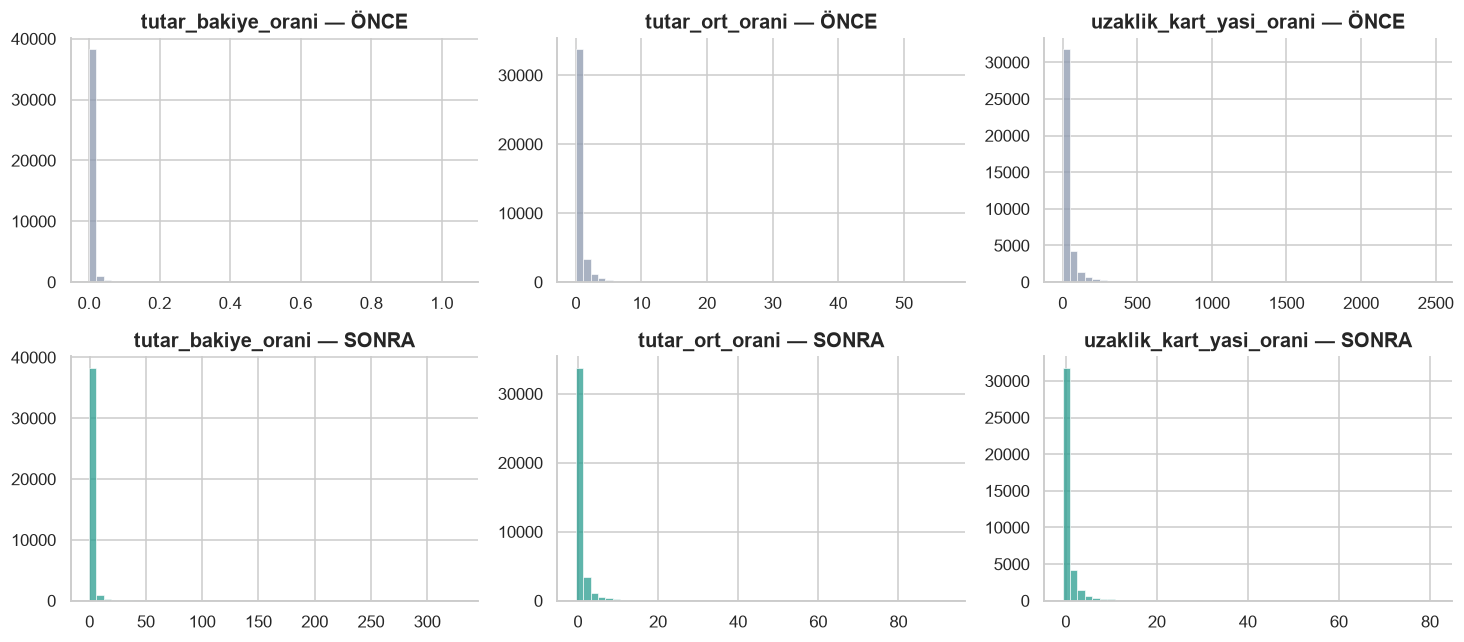

In [31]:
# Ölçekleme öncesi / sonrası karşılaştırma (en çarpık 3 sütun)
goster = carpiklik.sort_values(ascending=False).head(3).index.tolist()
if goster:
    fig, axes = plt.subplots(2, len(goster), figsize=(4.5 * len(goster), 6), squeeze=False)
    for j, c in enumerate(goster):
        sns.histplot(X_train[c], bins=50, color="#8d99ae", ax=axes[0, j]); axes[0, j].set_title(f"{c} — ÖNCE")
        sns.histplot(X_train_s[c], bins=50, color="#2a9d8f", ax=axes[1, j]); axes[1, j].set_title(f"{c} — SONRA")
        for i in (0, 1):
            axes[i, j].set_xlabel(""); axes[i, j].set_ylabel("")
    plt.tight_layout(); plt.show()

## 19. Özellik Seçimi (Feature Selection) 🎯

Çok özellik = daha yavaş eğitim + gürültü + overfitting riski. **Model eğitmeden** 4 adımda eliyoruz:

1. **Sabit / neredeyse sabit sütunlar** → bilgi taşımaz
2. **Yüksek korelasyon filtresi (|r| > 0.95)** → birbirinin kopyası olanlardan hedefle daha az ilişkili olanı at
3. **Mutual Information (MI)** → özelliğin hedef hakkında ne kadar bilgi verdiğini ölçer; **doğrusal olmayan** ilişkileri de yakalar
4. **ANOVA F-testi** → grup ortalamaları (fraud vs normal) arasındaki ayrışmayı ölçer (doğrusal)

Sonra MI ve F sıralamalarının ortalamasına göre **en iyi K özelliği** seçiyorum.
MI için fraud'lar çok az olduğundan **dengelenmiş bir örnek** kullanıyorum (sadece sıralama için; veri setini değiştirmez).

In [32]:
OZELLIK_SAYISI = 20     # ✏️ en fazla kaç özellik seçilsin

# --- Adım 1: sabit / neredeyse sabit sütunlar ---
sabit = [c for c in X_train_s.columns if X_train_s[c].nunique() <= 1]
nadir_ikili = [c for c in ikili_kolonlar if c in X_train_s.columns and min(X_train_s[c].mean(), 1 - X_train_s[c].mean()) < 0.0005]
at1 = sorted(set(sabit + nadir_ikili))
print("Adım 1 → atılan (sabit/çok nadir):", at1)
kalan = [c for c in X_train_s.columns if c not in at1]

# --- Adım 2: yüksek korelasyon filtresi ---
ornek_kor = X_train_s[kalan].sample(min(len(X_train_s), 200_000), random_state=RANDOM_STATE)
kor = ornek_kor.corr().abs()
hedef_k = ornek_kor.corrwith(y_train.loc[ornek_kor.index]).abs().fillna(0)
at2 = set()
for i, c1 in enumerate(kor.columns):
    for c2 in kor.columns[:i]:
        if kor.loc[c2, c1] > 0.95 and c1 not in at2 and c2 not in at2:
            at2.add(c1 if hedef_k[c1] < hedef_k[c2] else c2)   # hedefle daha az ilişkili olanı at
print("Adım 2 → atılan (yüksek korelasyonlu kopyalar):", sorted(at2))
kalan = [c for c in kalan if c not in at2]
print(f"Kalan özellik sayısı: {len(kalan)}")

Adım 1 → atılan (sabit/çok nadir): []
Adım 2 → atılan (yüksek korelasyonlu kopyalar): []
Kalan özellik sayısı: 41


✅ Seçilen 20 özellik:
 ['Failed_Transaction_Count_7d', 'Risk_Score', 'basarisiz_gunluk_orani', 'Transaction_Type_POS', 'uzaklik_kart_yasi_orani', 'gece_mi', 'Merchant_Category_Restaurants', 'Location_New York', 'Card_Type_Discover', 'Avg_Transaction_Amount_7d_log', 'saat', 'Authentication_Method_OTP', 'Device_Type_Tablet', 'Card_Type_Visa', 'Location_Mumbai', 'ay', 'Merchant_Category_Groceries', 'Authentication_Method_Password', 'Device_Type_Mobile', 'Daily_Transaction_Count']


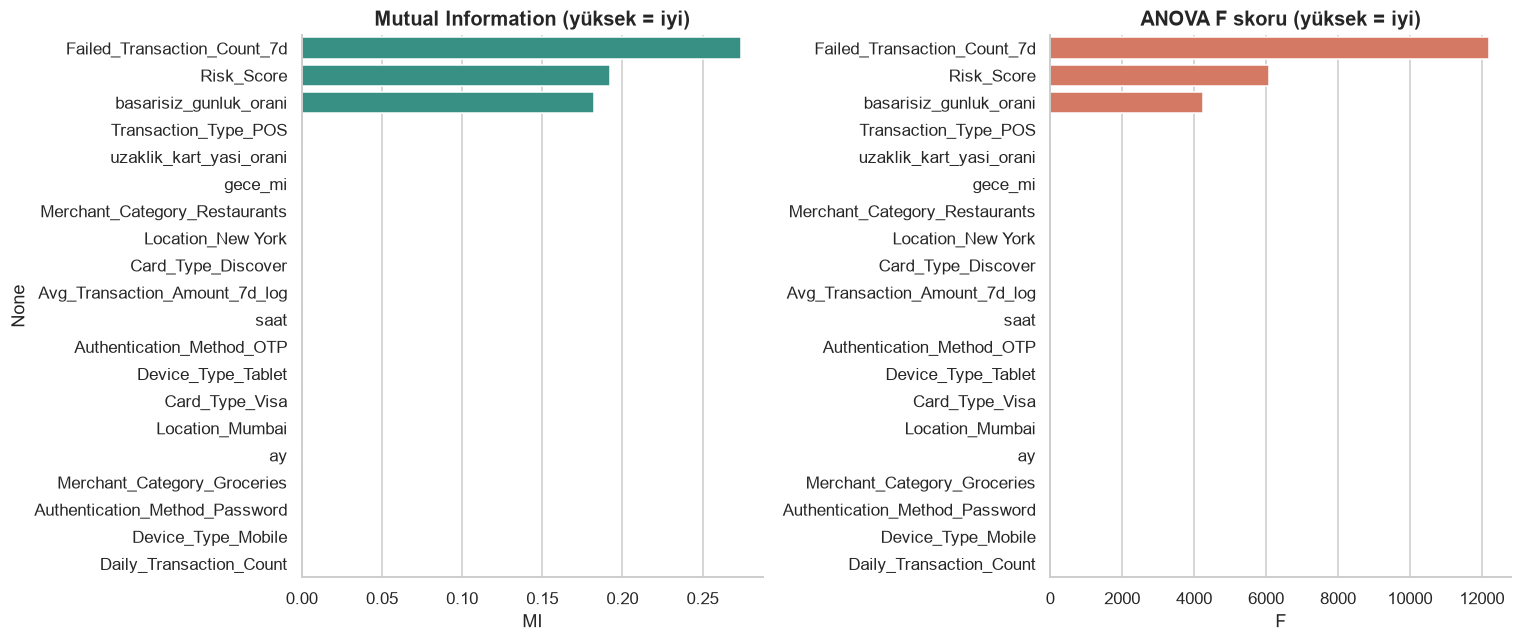

In [33]:
from sklearn.feature_selection import mutual_info_classif, f_classif

# --- Adım 3 ve 4: MI ve F-testi (dengelenmiş örnek üzerinde) ---
f_idx = y_train[y_train == 1].index
n_idx = y_train[y_train == 0].index
secim = f_idx.to_series().sample(min(len(f_idx), 10_000), random_state=RANDOM_STATE).index.append(
        n_idx.to_series().sample(min(len(n_idx), 40_000), random_state=RANDOM_STATE).index)
Xm, ym = X_train_s.loc[secim, kalan], y_train.loc[secim]

mi = mutual_info_classif(Xm, ym, discrete_features=[c in ikili_kolonlar for c in kalan], random_state=RANDOM_STATE)
F, _ = f_classif(Xm, ym)

skor = pd.DataFrame({"MI": mi, "F": np.nan_to_num(F)}, index=kalan)
# İki sıralamanın ortalaması: küçük = daha iyi
skor["ortalama_sira"] = (skor["MI"].rank(ascending=False) + skor["F"].rank(ascending=False)) / 2
skor = skor.sort_values("ortalama_sira")

secilen = skor.head(OZELLIK_SAYISI).index.tolist()
print(f"✅ Seçilen {len(secilen)} özellik:\n", secilen)

fig, ax = plt.subplots(1, 2, figsize=(14, max(4, len(secilen) * 0.3)))
top = skor.head(OZELLIK_SAYISI)
sns.barplot(x=top["MI"], y=top.index, color="#2a9d8f", ax=ax[0]); ax[0].set_title("Mutual Information (yüksek = iyi)")
sns.barplot(x=top["F"], y=top.index, color="#e76f51", ax=ax[1]); ax[1].set_title("ANOVA F skoru (yüksek = iyi)")
ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

## 20. Sonuçları Kaydetme 💾
Seçilen özelliklerle ölçeklenmiş train/test verisini `islenmis_veri/` klasörüne yazıyorum. Model aşamasında doğrudan bunları okuyabilirsin.

In [34]:
os.makedirs("islenmis_veri", exist_ok=True)
X_train_sel, X_test_sel = X_train_s[secilen], X_test_s[secilen]

pd.concat([X_train_sel, y_train.rename(T)], axis=1).to_csv("islenmis_veri/train.csv", index=False)
pd.concat([X_test_sel, y_test.rename(T)], axis=1).to_csv("islenmis_veri/test.csv", index=False)
with open("islenmis_veri/secilen_ozellikler.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(secilen))

print("Kaydedildi → islenmis_veri/train.csv, test.csv, secilen_ozellikler.txt")
print(f"Train: {X_train_sel.shape} | Test: {X_test_sel.shape} | Hedef: '{T}'")
X_train_sel.head()

Kaydedildi → islenmis_veri/train.csv, test.csv, secilen_ozellikler.txt
Train: (40000, 20) | Test: (10000, 20) | Hedef: 'Fraud_Label'


,Failed_Transaction_Count_7d,Risk_Score,basarisiz_gunluk_orani,Transaction_Type_POS,uzaklik_kart_yasi_orani,gece_mi,Merchant_Category_Restaurants,Location_New York,Card_Type_Discover,Avg_Transaction_Amount_7d_log,saat,Authentication_Method_OTP,Device_Type_Tablet,Card_Type_Visa,Location_Mumbai,ay,Merchant_Category_Groceries,Authentication_Method_Password,Device_Type_Mobile,Daily_Transaction_Count
3133,0.7072,0.0518,0.5172,1,-0.3961,1,0,0,0,-1.1218,-1.5188,0,0,0,0,0.1382,1,0,1,-0.3690
5433,-0.7054,0.8133,0.2414,0,2.6340,0,0,0,0,0.0740,0.5064,0,0,0,0,-1.6046,0,1,1,-1.3604
7621,-0.7054,-1.0669,-0.3621,0,0.6194,0,1,0,0,0.0258,-0.3616,1,0,0,0,-0.7332,0,0,1,-0.1212
22601,-0.7054,0.2271,-0.4608,0,-0.3077,0,0,0,1,-0.3920,0.6511,1,0,0,0,1.0096,0,0,1,0.6224
40066,0.7072,0.0209,0.2414,0,-0.1380,1,0,0,0,-1.0654,-1.5188,0,0,0,1,-1.6046,0,0,1,0.1267


## ✅ Özet ve Sıradaki Adımlar

**Yapılanlar:** EDA (istatistik, histogram, boxplot, scatter, korelasyon, kategorik, zaman) → özellik üretimi → encoding → ölçekleme → özellik seçimi.

**Model aşamasında dikkat edilecekler (henüz başlamadık):**
1. **Dengesizlik:** `class_weight="balanced"` veya SMOTE / undersampling — **sadece train'e** uygula, test'e asla.
2. **Metrik:** Accuracy değil → **PR-AUC (Average Precision), Recall, Precision, F1**. Karışıklık matrisine (confusion matrix) bak.
3. **Eşik (threshold) ayarı:** 0.5 genelde fraud için yanlış eşiktir; PR eğrisinden seç.
4. **Çapraz doğrulama:** `StratifiedKFold`.
5. **Aday modeller:** Lojistik Regresyon (taban çizgi), Random Forest, XGBoost/LightGBM, Isolation Forest (denetimsiz karşılaştırma).